<a href="https://colab.research.google.com/github/rinesl/Entity-resolution-febrl3/blob/main/febrl3-entity-resolution-1M_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entity Resolution at Scale: 1M Person Records in PySpark

**Author:** Fengting (Jessica) Jiang
**Runtime:** Google Colab (CPU) or Databricks
**Data:** synthetic person records (about 1M), built from the Febrl 3 vocabulary
**Version:** v2. v1 was the 5,000 record Febrl notebook in pandas.

## 1. Overview

# **The business problem**

The customer data has the same person entered many times, with typos, old addresses, different phone formats and missing emails. Without a way to link those records:

we count more customers than we really have
each customer’s history is scattered across several records
we risk mixing two customers together, which exposes one person’s data to another

**Error & Risk**
| Error | What happens | Why it matters |
|---|---|---|
| Over merge (false merge) | two people end up with one ID | wrong targeting, and one person's data is exposed to another (privacy risk) |
| Under merge (split) | one person ends up with several IDs | inflated counts, broken customer history |

### What I changed from v1
After review, I made three upgrades:

| # | Feedback | What I did |
|---|---|---|
| 1 | 5,000 records doesn't show scale | Reran the whole pipeline on about 1M records in PySpark (blocking joins, Spark ML, connected components in Spark) |
| 2 | Report errors at cluster level | Measured over merge vs. under merge on the final clusters, plus B cubed precision and recall |
| 3 | Answer the privacy requirement | Hashed email and phone with a secret key (salted hash) and compared accuracy against matching on the raw fields |

I also added three tests based on how identity graphs are run in practice: **match confidence** (a calibrated score per link, with tiers), **graph stability** (do IDs stay the same when the graph is rebuilt), and a **household layer** above person IDs.

### Success criteria
I set these before running anything so the results have something to be judged against.

| Area | Metric | Target |
|---|---|---|
| Blocking | pair completeness (true pairs kept) | at least 95% |
| Pair matching | precision on held out pairs | at least 98% (business choice) |
| Clusters | exact reconstruction rate, over merged clusters, split people | report and explain |
| Privacy | recall lost by using hashed email/phone instead of raw | small enough to accept the privacy gain |
| Confidence | calibration error (ECE) after calibration | close to 0 (under 0.02) |
| Stability | stable ID changed % when next month's data arrives | low, and mostly fixes rather than damage |
| Household | household members kept as separate people but linked into one household | report and explain |

### Scope and assumptions
1. All data is synthetic. No real PII is used anywhere.
2. `true_person_id` and `true_household_id` are ground truth. I only use them for evaluation, never as features.
3. Labels for training come from ground truth here. In a real project they would come from a manual review sample.

### Notebook flow
| Section | Content |
|---|---|
| 2 | Setup |
| 3 | Data: generate and profile |
| 4 | Data prep: standardize and hash identifiers |
| 5 | Test 1: blocking coverage |
| 6 | Features |
| 7 | Test 2: pair matching model and cutoff |
| 8 | Test 3: clustering and cluster level errors |
| 9 | Test 4: privacy, raw vs. hashed |
| 10 | Test 5: match confidence |
| 11 | Test 6: graph stability over time |
| 12 | Test 7: person vs. household |
| 13 | Error analysis |
| 14 | Results summary |
| 15 | Limitations and next steps |

## 2. Setup
`N_PEOPLE` controls the size. 400,000 people gives about 1.07M records since each person gets 0 to 5 duplicates. I'd start with 20,000 (about 55k records) to make sure everything runs, then switch to the full size.

In [1]:
!pip install -q pyspark recordlinkage rapidfuzz pyarrow
!which java || (apt-get -qq update && apt-get -qq install -y openjdk-17-jdk-headless > /dev/null)

/usr/bin/java


In [2]:
import os, hmac, hashlib, secrets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recordlinkage.datasets import load_febrl3

from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.functions import vector_to_array

N_PEOPLE = 400_000         # about 1.07M records; use 20_000 for a quick test run
RANDOM_STATE = 42
PRECISION_TARGET = 0.98    # business decision
MAX_BLOCK = 500            # skip blocks bigger than this so one bad key can't blow up the join
OUT = 'er_output'
os.makedirs('images', exist_ok=True)

spark = (SparkSession.builder
         .appName('entity-resolution-1m')
         .master('local[*]')
         .config('spark.driver.memory', '6g')
         .config('spark.sql.shuffle.partitions', '64')
         .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
         .getOrCreate())
spark.sparkContext.setLogLevel('WARN')
print('Spark', spark.version)

# keep every headline number in one place for the summary table at the end
metrics = {}
def log_metric(name, value):
    metrics[name] = value
    print(f'{name}: {value}')

Spark 4.0.5


## 3. Data

### 3.1 Generate the synthetic population
Febrl 3 only has 5,000 records and no email or phone, so it can't test either scale or the hashing question. I reuse its vocabulary (names, streets, suburb/postcode/state from the original records) and generate a bigger population where I still know the truth.

I built in the error patterns I've seen in customer data, since each one breaks a different part of the pipeline. These are the rates I set in the generator; 3.3 checks what actually ended up in the data, and 3.4 covers how I'd find these patterns in real data where there's no ground truth.

| Pattern | Design rate | What it tests |
|---|---|---|
| Households (same surname and address, half share a landline) | 15% of people | the main cause of false merges |
| Typos in names, street, suburb | 8 to 12% per field | fuzzy matching |
| First and last name swapped / surname changed | 2% / 2% | rules that rely on names only |
| Moved to a new address | 5% | address evidence goes away, contact data has to carry the match |
| DOB digit typo / day and month swapped | 5% / 3% | partial date evidence |
| Email: format noise / typo / new email / missing | 15% / 5% / 8% / 10% | hashed (exact) vs. raw (fuzzy) |
| Phone: +61, spaces, dashes / digit typo / new number / missing | 30% / 4% / 8% / 15% | why normalizing before hashing matters |

In [3]:
def make_vocab(febrl):
    # use the original records only, the duplicates already contain typos
    org = febrl[febrl.index.str.endswith('-org')]
    # keep suburb, postcode and state together so locations stay realistic
    loc = (org[['suburb', 'postcode', 'state']].dropna().drop_duplicates()
           .to_records(index=False).tolist())
    return {
        'given': org['given_name'].dropna().unique(),
        'surname': org['surname'].dropna().unique(),
        'street': org['address_1'].dropna().unique(),
        'addr2': org['address_2'].dropna().unique(),
        'loc': loc,
    }

# 10 most common email domains (gmass.co list), weighted by rank
DOMAINS = np.array(['gmail.com', 'yahoo.com', 'hotmail.com', 'aol.com', 'outlook.com',
                    'comcast.net', 'icloud.com', 'msn.com', 'hotmail.co.uk', 'sbcglobal.net'])
LETTERS = np.array(list('abcdefghijklmnopqrstuvwxyz'))


def typo(s, rng):
    # one keyboard style error: replace, drop, insert or swap a character
    if not isinstance(s, str) or len(s) < 2:
        return s
    i = rng.integers(0, len(s) - 1)
    op = rng.integers(0, 4)
    if op == 0:
        return s[:i] + rng.choice(LETTERS) + s[i + 1:]
    if op == 1:
        return s[:i] + s[i + 1:]
    if op == 2:
        return s[:i] + rng.choice(LETTERS) + s[i:]
    return s[:i] + s[i + 1] + s[i] + s[i + 2:]


def digit_typo(s, rng):
    if not isinstance(s, str) or len(s) < 2:
        return s
    i = rng.integers(0, len(s))
    return s[:i] + str(rng.integers(0, 10)) + s[i + 1:]


def generate_people(n, vocab, rng, household_rate=0.15):
    # one clean record per real person
    p = pd.DataFrame({
        'true_person_id': np.arange(n),
        'given_name': rng.choice(vocab['given'], n),
        'surname': rng.choice(vocab['surname'], n),
        'street_number': rng.integers(1, 400, n).astype(str),
        'address_1': rng.choice(vocab['street'], n),
        'address_2': np.where(rng.random(n) < 0.6, rng.choice(vocab['addr2'], n), None),
    })
    locs = np.array(vocab['loc'], dtype=object)[rng.integers(0, len(vocab['loc']), n)]
    p['suburb'], p['postcode'], p['state'] = locs[:, 0], locs[:, 1], locs[:, 2]
    dob = pd.Timestamp('1925-01-01') + pd.to_timedelta(rng.integers(0, 80 * 365, n), unit='D')
    p['date_of_birth'] = dob.strftime('%Y%m%d')
    p['phone'] = '04' + pd.Series(rng.integers(0, 10**8, n)).astype(str).str.zfill(8).values

    # households: copy surname and address from a "head" person, and the phone half the time
    is_member = rng.random(n) < household_rate
    members = np.flatnonzero(is_member)
    heads = rng.choice(np.flatnonzero(~is_member), len(members))   # heads are never members themselves
    for col in ['surname', 'street_number', 'address_1', 'address_2', 'suburb', 'postcode', 'state']:
        p.loc[members, col] = p[col].values[heads]
    share_phone = rng.random(len(members)) < 0.5
    p.loc[members[share_phone], 'phone'] = p['phone'].values[heads[share_phone]]
    # household ground truth (evaluation only, Test 7)
    p['true_household_id'] = p['true_person_id']
    p.loc[members, 'true_household_id'] = heads

    # email built from the name in a few common patterns, one mailbox per person
    pattern = rng.integers(0, 4, n)
    g, s = p['given_name'].values.astype(str), p['surname'].values.astype(str)
    local = np.select(
        [pattern == 0, pattern == 1, pattern == 2],
        [np.char.add(np.char.add(g, '.'), s),
         np.char.add(g, s),
         np.char.add(np.array([x[0] for x in g]), s)],
        default=np.char.add(np.char.add(g, '_'), s))
    suffix = np.where(rng.random(n) < 0.4, pd.Series(rng.integers(1, 99, n)).astype(str).values, '')
    email = pd.Series(np.char.add(np.char.add(np.char.add(local, suffix), '@'), rng.choice(DOMAINS, n)))
    dup = email.duplicated(keep='first')
    email[dup] = [e.replace('@', f'.{pid}@', 1) for e, pid in zip(email[dup], p.loc[dup, 'true_person_id'])]
    p['email'] = email.values
    return p


def corrupt(dups, vocab, rng):
    # add common errors to the duplicate records (rates are per record, per field)
    d = dups.copy()
    m = len(d)

    def apply(col, rate, fn):
        idx = np.flatnonzero(rng.random(m) < rate)
        vals = d[col].to_numpy(dtype=object, copy=True)
        vals[idx] = [fn(v) for v in vals[idx]]
        d[col] = vals

    def blank(col, rate):
        d.loc[rng.random(m) < rate, col] = None

    # names
    apply('given_name', 0.12, lambda v: typo(v, rng)); blank('given_name', 0.03)
    apply('surname', 0.12, lambda v: typo(v, rng)); blank('surname', 0.02)
    swap = rng.random(m) < 0.02
    d.loc[swap, ['given_name', 'surname']] = d.loc[swap, ['surname', 'given_name']].values
    changed = rng.random(m) < 0.02                     # e.g. surname change after marriage
    d.loc[changed, 'surname'] = rng.choice(vocab['surname'], changed.sum())

    # address: a full move, or small errors in single fields
    moved = np.flatnonzero(rng.random(m) < 0.05)
    locs = np.array(vocab['loc'], dtype=object)[rng.integers(0, len(vocab['loc']), len(moved))]
    d.iloc[moved, d.columns.get_loc('address_1')] = rng.choice(vocab['street'], len(moved))
    d.iloc[moved, d.columns.get_loc('street_number')] = rng.integers(1, 400, len(moved)).astype(str)
    for j, col in enumerate(['suburb', 'postcode', 'state']):
        d.iloc[moved, d.columns.get_loc(col)] = locs[:, j]
    apply('street_number', 0.05, lambda v: digit_typo(v, rng)); blank('street_number', 0.05)
    apply('address_1', 0.10, lambda v: typo(v, rng)); blank('address_1', 0.03)
    apply('address_2', 0.08, lambda v: typo(v, rng)); blank('address_2', 0.10)
    apply('suburb', 0.08, lambda v: typo(v, rng)); blank('suburb', 0.02)
    apply('postcode', 0.05, lambda v: digit_typo(v, rng))

    # date of birth: digit typo, day/month swapped, missing
    apply('date_of_birth', 0.05, lambda v: digit_typo(v, rng))
    apply('date_of_birth', 0.03, lambda v: v[:4] + v[6:8] + v[4:6] if isinstance(v, str) else v)
    blank('date_of_birth', 0.03)

    # email: case/space noise (normalizing fixes this), typo, new email, missing
    apply('email', 0.15, lambda v: rng.choice([v.upper(), ' ' + v, v.title() + ' ']) if isinstance(v, str) else v)
    apply('email', 0.05, lambda v: typo(v, rng))
    new_email = rng.random(m) < 0.08
    d.loc[new_email, 'email'] = (d.loc[new_email, 'given_name'].fillna('x').astype(str) + '.'
                                 + pd.Series(rng.integers(100, 9999, new_email.sum()), index=d.index[new_email]).astype(str)
                                 + '@' + rng.choice(DOMAINS, new_email.sum()))
    blank('email', 0.10)

    # phone: different formats, digit typo, new number, missing
    def fmt_phone(v):
        if not isinstance(v, str):
            return v
        k = rng.integers(0, 3)
        if k == 0:
            return '+61 ' + v[1:4] + ' ' + v[4:7] + ' ' + v[7:]
        if k == 1:
            return v[:4] + '-' + v[4:7] + '-' + v[7:]
        return '(' + v[:2] + ') ' + v[2:6] + ' ' + v[6:]
    apply('phone', 0.30, fmt_phone)
    apply('phone', 0.04, lambda v: digit_typo(v, rng))
    new_phone = rng.random(m) < 0.08
    d.loc[new_phone, 'phone'] = '04' + pd.Series(rng.integers(0, 10**8, new_phone.sum())).astype(str).str.zfill(8).values
    blank('phone', 0.15)
    return d

# each person gets 0 to 5 duplicates, about 2.7 records per person on average
def generate_records(n_people, vocab, seed=42):
    rng = np.random.default_rng(seed)
    people = generate_people(n_people, vocab, rng)
    n_dups = rng.choice([0, 1, 2, 3, 4, 5], n_people, p=[0.20, 0.35, 0.20, 0.12, 0.08, 0.05])
    dups = corrupt(people.loc[people.index.repeat(n_dups)].reset_index(drop=True), vocab, rng)
    people['record_type'], dups['record_type'] = 'org', 'dup'
    recs = pd.concat([people, dups], ignore_index=True)
    recs = recs.sample(frac=1, random_state=seed).reset_index(drop=True)
    recs.insert(0, 'rec_id', np.arange(len(recs), dtype=np.int64))
    return recs

# next month's feed: new duplicates of existing people, plus brand new people with their own duplicates
def generate_batch(org, vocab, frac_existing, n_new_people, person_offset, start_rec_id, seed=7):
    rng = np.random.default_rng(seed)
    org = org.astype(object).where(org.notna(), None)
    returning = corrupt(org.sample(frac=frac_existing, random_state=seed).reset_index(drop=True), vocab, rng)
    new = generate_people(n_new_people, vocab, rng)
    new['true_person_id'] += person_offset
    new['true_household_id'] += person_offset
    n_dups = rng.choice([0, 1, 2], n_new_people, p=[0.5, 0.35, 0.15])
    new_dups = corrupt(new.loc[new.index.repeat(n_dups)].reset_index(drop=True), vocab, rng)
    returning['record_type'], new['record_type'], new_dups['record_type'] = 'dup', 'org', 'dup'
    batch = pd.concat([returning, new, new_dups], ignore_index=True).sample(frac=1, random_state=seed)
    batch = batch.drop(columns=['rec_id'], errors='ignore').reset_index(drop=True)
    batch.insert(0, 'rec_id', np.arange(start_rec_id, start_rec_id + len(batch), dtype=np.int64))
    return batch

In [4]:
%%time
vocab = make_vocab(load_febrl3())
recs_pd = generate_records(N_PEOPLE, vocab, seed=RANDOM_STATE)

# write to parquet with everything as string, then Spark takes over from here
str_cols = [c for c in recs_pd.columns if c not in ('rec_id', 'true_person_id', 'true_household_id')]
recs_pd[str_cols] = recs_pd[str_cols].astype('string')
recs_pd.to_parquet('raw_records.parquet', index=False)
del recs_pd

raw = spark.read.parquet('raw_records.parquet').repartition(16).cache()
n_records = raw.count()
log_metric('records', n_records)
log_metric('true people', raw.select('true_person_id').distinct().count())
raw.show(5, truncate=False)

records: 1070421
true people: 400000
+------+--------------+----------+----------+-------------+---------------+---------+---------+--------+-----+-------------+------------+-----------------+------------------------+-----------+
|rec_id|true_person_id|given_name|surname   |street_number|address_1      |address_2|suburb   |postcode|state|date_of_birth|phone       |true_household_id|email                   |record_type|
+------+--------------+----------+----------+-------------+---------------+---------+---------+--------+-----+-------------+------------+-----------------+------------------------+-----------+
|985097|368468        |anastasia |kidsley   |121          |chave street   |occar    |bilbul   |4226    |wa   |19950927     |0491-138-263|368468           |NULL                    |dup        |
|910162|358860        |jesse     |stoneman  |317          |searel place   |NULL     |mill park|5031    |nsw  |19921214     |NULL        |203390           |jesse.9729@comcast.net  |dup        

In [5]:
# ground truth pairs, use for evaluation only
gt = raw.select('rec_id', 'true_person_id')
true_pairs = (gt.alias('a').join(gt.alias('b'), 'true_person_id')
              .where(F.col('a.rec_id') < F.col('b.rec_id'))
              .select(F.col('a.rec_id').alias('id_l'), F.col('b.rec_id').alias('id_r'))
              .cache())
n_true_pairs = true_pairs.count()
all_pairs = n_records * (n_records - 1) // 2
log_metric('true duplicate pairs', n_true_pairs)
log_metric('all possible pairs', f'{all_pairs:,}')

true duplicate pairs: 1284525
all possible pairs: 572,900,023,410


### 3.2 Data profile
Same check as v1: which fields are filled in often enough to block or match on.

In [6]:
fields = ['given_name', 'surname', 'street_number', 'address_1', 'address_2', 'suburb',
          'postcode', 'date_of_birth', 'email', 'phone']
profile = raw.select([(F.avg(F.col(c).isNull().cast('double')) * 100).alias(c) for c in fields]).toPandas()
profile.T.rename(columns={0: 'missing %'}).round(1)

,missing %
given_name,1.9
surname,1.3
street_number,3.1
address_1,1.9
address_2,43.8
suburb,1.3
postcode,0.0
date_of_birth,1.9
email,6.3
phone,9.4


**Note:** names, DOB and postcode are almost always there, so they work as blocking keys. `address_2` is missing for close to half the records, so it only goes into the combined address string. Email and phone are missing on more records than names (roughly 6% and 9%, all on duplicates), so they can help a match but can't be the only route to one.

### 3.3 Check the generated patterns
The rates in 3.1 are inputs. Before I trust any result, I want to see what actually landed in the data, so I compare every duplicate with the original record of the same person.

In [7]:
recs_chk = pd.read_parquet('raw_records.parquet')

# compare every duplicate with the original record of the same person
org = recs_chk[recs_chk['record_type'] == 'org'].set_index('true_person_id')
dup = recs_chk[recs_chk['record_type'] == 'dup']
o = org.loc[dup['true_person_id']].reset_index(drop=True)
d = dup.reset_index(drop=True)

# both present and different
def changed(col):
    return (d[col].notna() & o[col].notna() & (d[col] != o[col])).mean()
# unique record no duplicate
def went_missing(col):
    return (d[col].isna() & o[col].notna()).mean()

email_d, email_o = d['email'].str.strip().str.lower(), o['email'].str.strip().str.lower()
phone_d = d['phone'].str.replace(r'\D', '', regex=True).str.replace(r'^61', '0', regex=True)
phone_o = o['phone'].str.replace(r'\D', '', regex=True)
moved = (d['address_1'] != o['address_1']) & (d['suburb'] != o['suburb']) & (d['postcode'] != o['postcode'])

# households: originals that share surname + street + suburb with at least one other person
hh_key = org['surname'] + '|' + org['street_number'] + '|' + org['address_1'] + '|' + org['suburb']

patterns = pd.Series({
    'household (shares surname + address with another person)': hh_key.duplicated(keep=False).mean(),
    'given name changed': changed('given_name'),
    'surname changed': changed('surname'),
    'given and surname swapped': ((d['given_name'] == o['surname']) & (d['surname'] == o['given_name'])).mean(),
    'moved (street, suburb and postcode all different)': moved.mean(),
    'street changed': changed('address_1'),
    'suburb changed': changed('suburb'),
    'postcode changed': changed('postcode'),
    'DOB changed': changed('date_of_birth'),
    'DOB day and month swapped': ((d['date_of_birth'] != o['date_of_birth'])
                                  #skip dates like 0505 where a swap changes nothing
                                  & (d['date_of_birth'] == o['date_of_birth'].str[:4] + o['date_of_birth'].str[6:8]
                                     + o['date_of_birth'].str[4:6])).mean(),
    'email format only (same after cleaning)': ((d['email'] != o['email']) & (email_d == email_o)).mean(),
    'email really different': (d['email'].notna() & (email_d != email_o)).mean(),
    'email missing': went_missing('email'),
    'phone format only (same digits)': ((d['phone'] != o['phone']) & (phone_d == phone_o)).mean(),
    'phone really different': (d['phone'].notna() & (phone_d != phone_o)).mean(),
    'phone missing': went_missing('phone'),
}).mul(100).round(1)
patterns.to_frame('% of duplicates (household row: % of people)')

,% of duplicates (household row: % of people)
household (shares surname + address with another person),28.7
given name changed,13.0
surname changed,14.9
given and surname swapped,1.5
"moved (street, suburb and postcode all different)",4.7
street changed,13.8
suburb changed,12.1
postcode changed,9.3
DOB changed,7.0
DOB day and month swapped,2.7


**Note:** The measured rates come out a bit different from the design rates, and that’s expected because errors stack. A surname typo and a surname change both show up as “surname changed”, a move also changes the street, suburb and postcode, and a swapped name that later gets a typo no longer looks swapped. Households show 28.7% of people because 15% join a household and the head they join is counted too. The missing rates (email 10%, phone 15%) match the design exactly, which tells me the generator is doing what I set. The rows that matter most for the rest of the notebook: 26.5% of duplicates have a phone that only differs in format and 13% have an email that only differs in case or spaces. A raw hash would miss all of those, which is why I clean before hashing (4.1, checked again in 9.1). About 10% of duplicates have a really different email or phone, which no exact token can catch. That’s the recall cost Test 4 measures.

### 3.4 How I'd find these patterns in real data
Here I know the truth because I generated it. In my AML work I didn't have that. When I grouped accounts into customers and households using KYC data (address, email, phone), nobody handed me a list of which records were the same person. Based on that work, this is how I'd find the patterns, roughly in this order:

**1. Data quality rules, no labels needed.** I start here because it's cheap and runs on the full population. I profile formats and look for values that are shared too widely to be real identifiers. In bank data this is where you find the phone stored three different ways across systems, placeholder values like `0000000000` or `noemail@bank.com`, and branch or business phones attached to hundreds of customers. Those have to be cleaned or excluded before matching, otherwise one shared value chains hundreds of people together. The cell below does this on the synthetic data.

**2. Known links between systems.** Some records already come linked, for example the same customer number on a credit card and a deposit account, or the same customer before and after a KYC refresh. Comparing those pairs field by field (the same comparison as 3.3) shows how a real customer's data drifts over time: how often the address changes, how often the phone gets updated.

**3. Manual review of a sample.** This is the only way to get real error rates and real labels. I'd pull a random sample of candidate pairs, stratified by score so reviewers see clear matches, clear non matches and the borderline ones, and have them label each pair match or not match with a reason ("same person, moved", "different people, same household"). I used the same approach for the labels in my NLP transaction classifier, where the labels came from reviewing a random sample of the in scope population. The reasons become the pattern table and the error analysis in section 13.

A couple of things that matter a lot on real data:
1. Write down the review guideline before anyone labels anything (for example, is a parent and adult child at the same address a match for a household ID but not for a person ID?). Different reviewers read the same pair differently, the same way teams read the same metric differently.
2. All of this runs inside PII controls: masked identifiers, a restricted environment, and only the fields reviewers need. Which is another reason to tokenize contact data early (section 9).

In [8]:
# data quality profile without labels: formats and over shared values
# (this is the check I'd run first on real customer data)

# phone formats: replace every digit with 9 to see the patterns
(raw.where(F.col('phone').isNotNull())
    .groupBy(F.regexp_replace('phone', '[0-9]', '9').alias('phone format'))
    .count().orderBy(F.desc('count')).show(20, truncate=False))

# email formats
email_dq = raw.where(F.col('email').isNotNull()).agg(
    F.count('*').alias('emails'),
    F.avg((F.col('email') != F.lower('email')).cast('double')).alias('has uppercase'),
    F.avg((F.col('email') != F.trim('email')).cast('double')).alias('leading/trailing space'),
    F.avg((~F.col('email').rlike(r'^[^@\s]+@[^@\s]+\.[^@\s]+$')).cast('double')).alias('invalid format'),
).toPandas().T.rename(columns={0: 'value'})
display(email_dq.round(4))

# shared identifiers: how many distinct surnames sit behind each phone and each address
# one person's records share a phone;
# many different surnames on one phone points to a household, business line or placeholder
def sharing(col_expr, label):
    return (raw.where(col_expr.isNotNull())
               .groupBy(col_expr.alias('v'))
               .agg(F.countDistinct('surname').alias('surnames'))
               .groupBy(F.when(F.col('surnames') >= 6, '6+')
               .otherwise(F.col('surnames')
               .cast('string')).alias('distinct surnames'))
               .count().withColumnRenamed('count', label))

phone_digits = F.regexp_replace('phone', '[^0-9]', '')

address = F.concat_ws(' ', F.lower('street_number'), F.lower('address_1'), F.lower('suburb'))
(sharing(phone_digits, 'phones').join(sharing(address, 'addresses'), 'distinct surnames', 'outer')
    .orderBy('distinct surnames').toPandas())

+---------------+------+
|phone format   |count |
+---------------+------+
|9999999999     |812714|
|(99) 9999 9999 |52305 |
|9999-999-999   |51655 |
|+99 999 999 999|51620 |
|99999999-999   |176   |
|9999-9999999   |174   |
|(999 9999 9999 |173   |
|(99)99999 9999 |156   |
|+99 9999999 999|149   |
|999) 9999 9999 |146   |
|+999999 999 999|140   |
|(99) 999999999 |138   |
|999 999 999 999|137   |
|+99 999 9999999|136   |
+---------------+------+



,value
emails,1.003483e+06
has uppercase,5.500000e-02
leading/trailing space,5.490000e-02
invalid format,6.890000e-02


,distinct surnames,phones,addresses
0,0,2163,4200
1,1,415047,482240
2,2,56733,55645
3,3,5705,6385
4,4,450,526
5,5,22,57
6,6+,2,9


**Note:**


1.   Phones: 812k are already clean 10 digit numbers. Each of the 3
added formats (brackets, dashes, +61) has about 52k. The small tail of odd shapes comes from typos that hit a separator, and cleaning can’t fix those (same as real data).
2.   Emails: 5.5% have uppercase and 5.5% have extra spaces. The 6.9% “invalid” is mostly those spaces; after trimming, only about 1.4% are truly broken. This is why 4.1 cleans before hashing.
3.   Sharing: most phones and addresses sit behind one surname. The 2 and 3 surname rows are mostly one person with a surname typo or name change, so surname count overstates sharing.

4.    On real data: I’d count resolved person IDs per phone or address instead, expect a long 6+ tail (branch phones, business lines, placeholders), and drop values shared by more than N customers from blocking.

## 4. Data prep

### 4.1 Standardize first, then hash
A hash is all or nothing. `Jane.Doe@Gmail.com ` and `jane.doe@gmail.com` give completely different hashes, so every field has to be cleaned before hashing:

| Field | Cleaning |
|---|---|
| email | trim, lower case |
| phone | keep digits only, turn `+61 4xx` into `04xx` so every number has one format |
| names, address | trim, lower case, Soundex code for blocking |

### 4.2 Salted hash (HMAC with a secret key)
I use HMAC SHA256 with a secret key instead of a plain SHA256. A plain hash of a phone number can be reversed by brute force since there are only about 100M mobile numbers. With a secret key, a leaked token table is useless without the key.

A few things I had to get right:
1. Every source has to use the same key, otherwise the same email gets different tokens and nothing matches. That's why a random salt per record (the password approach) doesn't work for matching.
2. In production the key sits in a secret manager and gets rotated with a plan to redo the tokens. Here I read it from an env var or generate one for the session.
3. Blocking keys are hashed too. Hashing keeps equality, so the candidate pairs are exactly the same whether the keys are raw or hashed. That keeps the raw vs. hashed comparison in Test 4 fair.

In [9]:
%%time
HASH_KEY = (os.environ.get('ER_HASH_KEY') or secrets.token_hex(32)).encode()# DO NOT PRINT THIS

@F.pandas_udf('string')
# missing stays missing, no token for "unknown"
def hmac_sha256(s: pd.Series) -> pd.Series:
    return s.map(lambda v: hmac.new(HASH_KEY, v.encode(), hashlib.sha256).hexdigest()
                 if isinstance(v, str) and v else None)

def norm(col):
    s = F.lower(F.trim(F.col(col)))
    return F.when(s == '', None).otherwise(s)

# composite key; concat gives null if any part is missing,
# so incomplete keys never block together
def key(*cols):
    parts = []
    for c in cols:
        parts += [c, F.lit('|')]
    return F.concat(*parts[:-1])

digits = F.regexp_replace(F.col('phone'), '[^0-9]', '')
phone_clean = (F.when((F.length(digits) == 11) & digits.startswith('61'),
                      F.concat(F.lit('0'), F.substring(digits, 3, 9)))
                .otherwise(digits))

# one token per identifier, plus a few partial tokens (Soundex, DOB year, DOB month+day)
# so the fully hashed model in Test 4 still gets some typo tolerance
token_src = {
    'email_h': F.col('email'), 'phone_h': F.col('phone'),
    'email_h_raw': F.col('email_raw'), 'phone_h_raw': F.col('phone_raw'),
    'given_h': F.col('given'), 'surname_h': F.col('surname'),
    'given_sdx_h': F.col('given_sdx'), 'surname_sdx_h': F.col('surname_sdx'),
    'name_set_h': F.col('name_set'),
    'dob_h': F.col('dob'), 'dob_year_h': F.substring('dob', 1, 4), 'dob_md_h': F.substring('dob', 5, 4),
    'postcode_h': F.col('postcode'), 'street_no_h': F.col('street_number'),
    'address1_h': F.col('address_1'), 'suburb_h': F.col('suburb'),
    #hashed blocking keys
    'bk_surname_dobym': key(F.col('surname_sdx'), F.substring('dob', 1, 6)),
    'bk_postcode_given': key(F.col('postcode'), F.col('given_sdx')),
    'bk_dob_initial': key(F.col('dob'), F.substring('given', 1, 1)),
    'bk_names_streetno': key(F.col('given_sdx'), F.col('surname_sdx'), F.col('street_number')),
    'bk_email': F.col('email'), 'bk_phone': F.col('phone'),
}

#standardize + hash; a function so next month's batch (Test 6) goes through exactly the same steps
def prepare(df):
    out = (df
        .select('rec_id', 'true_person_id', 'true_household_id',
                norm('given_name').alias('given'), norm('surname').alias('surname'),
                norm('street_number').alias('street_number'), norm('address_1').alias('address_1'),
                norm('address_2').alias('address_2'), norm('suburb').alias('suburb'),
                norm('postcode').alias('postcode'), norm('date_of_birth').alias('dob'),
                norm('email').alias('email'),
                F.when(F.length(phone_clean) >= 8, phone_clean).alias('phone'),
                F.col('email').alias('email_raw'), F.col('phone').alias('phone_raw'))   # uncleaned, for the check in Test 4
        .withColumn('email', F.when(F.col('email').contains('@'), F.col('email')))
        .withColumn('given_sdx', F.soundex('given'))
        .withColumn('surname_sdx', F.soundex('surname'))
        .withColumn('full_address', F.trim(F.regexp_replace(
            F.concat_ws(' ', 'street_number', 'address_1', 'address_2', 'suburb'), ' +', ' ')))
        #names in alphabetical order, so a first/last swap still gives the same value
        .withColumn('name_set', F.when(F.col('given').isNotNull() & F.col('surname').isNotNull(),
                                       key(F.least('given', 'surname'), F.greatest('given', 'surname')))))
    for name, expr in token_src.items():
        out = out.withColumn(name, hmac_sha256(expr))
    return out

prepare(raw).drop('email_raw', 'phone_raw').write.mode('overwrite').parquet(f'{OUT}/records')
recs = spark.read.parquet(f'{OUT}/records').cache()
recs.count()
recs.select('rec_id', 'given', 'surname', 'email', 'phone', 'email_h', 'phone_h').show(3, truncate=24)

+------+------+--------+------------------------+----------+------------------------+------------------------+
|rec_id| given| surname|                   email|     phone|                 email_h|                 phone_h|
+------+------+--------+------------------------+----------+------------------------+------------------------+
|339394|   mia|  rundle|      mia_rundle@aol.com|      NULL|43c71a0b0b3041e75669d...|                    NULL|
|824415|ashlie| banelis|ashlie_banelis@icloud...|0469490528|2afbe3d7dc05603f68166...|a8e272157032137cf7c00...|
|527924| aiden|sounness|aidensounness@outlook...|0438483674|8bce78010d95617871e55...|df9767e5367ee0a7ba2f6...|
+------+------+--------+------------------------+----------+------------------------+------------------------+
only showing top 3 rows
CPU times: user 171 ms, sys: 39.9 ms, total: 211 ms
Wall time: 3min 53s


## 5. Test 1: Blocking coverage

**Goal:** cut 1M records (about 5.7 x 10^11 possible pairs) down to a few million candidate pairs without losing true matches.

**Setup:** six blocking passes. A pair is kept if any pass keeps it. All keys are hashed tokens.

| Pass | Key | What it catches |
|---|---|---|
| 1 | surname Soundex + birth year and month | surname spelling variants |
| 2 | postcode + first name Soundex | DOB typos |
| 3 | exact DOB + first initial | surname changes, moves |
| 4 | first + last name Soundex + street number | postcode typos, missing DOB |
| 5 | hashed email | moves plus name changes |
| 6 | hashed phone | moves plus name changes |

Blocks over `MAX_BLOCK` records get skipped and logged, so one skewed key (like a shared landline) can't blow up the join.

**What I look at:** candidate pairs, reduction ratio, and pair completeness for each pass, for passes 1 to 4 only, and for all six combined.

In [10]:
BLOCK_PASSES = ['bk_surname_dobym', 'bk_postcode_given', 'bk_dob_initial',
                'bk_names_streetno', 'bk_email', 'bk_phone']
CONTACT_PASSES = ['bk_email', 'bk_phone']

#self join on one key, returns pairs with id_l < id_r
def block_pairs(df, key_col):
    b = df.select('rec_id', F.col(key_col).alias('k')).where(F.col('k').isNotNull())
    sizes = b.groupBy('k').count()
    skipped = sizes.where(F.col('count') > MAX_BLOCK).count()
    b = b.join(sizes.where((F.col('count') >= 2) & (F.col('count') <= MAX_BLOCK)).select('k'), 'k')
    pairs = (b.alias('l').join(b.alias('r'), 'k')
             .where(F.col('l.rec_id') < F.col('r.rec_id'))
             .select(F.col('l.rec_id').alias('id_l'), F.col('r.rec_id').alias('id_r'))
             .withColumn('pass', F.lit(key_col)))
    return pairs, skipped

In [11]:
%%time
union = None
for k in BLOCK_PASSES:
    p, skipped = block_pairs(recs, k)
    if skipped:
        print(f'{k}: skipped {skipped} oversized blocks')
    union = p if union is None else union.unionByName(p)
candidates = union.groupBy('id_l', 'id_r').agg(F.collect_set('pass').alias('passes'))

#attach ground truth to each candidate (evaluation only)
tp_l = gt.select(F.col('rec_id').alias('id_l'), F.col('true_person_id').alias('person_l'))
tp_r = gt.select(F.col('rec_id').alias('id_r'), F.col('true_person_id').alias('person_r'))
candidates = (candidates.join(tp_l, 'id_l').join(tp_r, 'id_r')
              .withColumn('label', (F.col('person_l') == F.col('person_r')).cast('double')))
candidates.write.mode('overwrite').parquet(f'{OUT}/candidates')
candidates = spark.read.parquet(f'{OUT}/candidates').cache()
n_cand = candidates.count()

CPU times: user 212 ms, sys: 52.4 ms, total: 265 ms
Wall time: 3min 50s


In [12]:
def completeness(df):
    return df.agg(F.sum('label')).first()[0] / n_true_pairs

rows = []
for k in BLOCK_PASSES:
    sub = candidates.where(F.array_contains('passes', k))
    rows.append({'pass': k, 'candidate pairs': sub.count(), 'pair completeness': round(completeness(sub), 4)})
no_contact = candidates.where(F.size(F.array_except('passes', F.array(*[F.lit(c) for c in CONTACT_PASSES]))) > 0)
rows.append({'pass': 'passes 1 to 4 (no email/phone)', 'candidate pairs': no_contact.count(),
             'pair completeness': round(completeness(no_contact), 4)})
rows.append({'pass': 'all 6 combined', 'candidate pairs': n_cand,
             'pair completeness': round(completeness(candidates), 4)})
blocking_results = pd.DataFrame(rows)
blocking_results['reduction ratio'] = (1 - blocking_results['candidate pairs'] / all_pairs).round(7)

log_metric('blocking: candidate pairs', n_cand)
log_metric('blocking: reduction ratio', round(1 - n_cand / all_pairs, 7))
log_metric('blocking: pair completeness', round(completeness(candidates), 4))
log_metric('blocking: pair completeness without email/phone', float(blocking_results.iloc[-2]['pair completeness']))
log_metric('candidate pairs that are true matches (%)', round(candidates.agg(F.avg('label')).first()[0] * 100, 2))
blocking_results

blocking: candidate pairs: 7096456
blocking: reduction ratio: 0.9999876
blocking: pair completeness: 0.991
blocking: pair completeness without email/phone: 0.9323
candidate pairs that are true matches (%): 17.94


,pass,candidate pairs,pair completeness,reduction ratio
0,bk_surname_dobym,1807955,0.7267,0.999997
1,bk_postcode_given,4638403,0.7310,0.999992
2,bk_dob_initial,2062529,0.7680,0.999996
3,bk_names_streetno,765261,0.5868,0.999999
4,bk_email,908595,0.7073,0.999998
5,bk_phone,1020399,0.6650,0.999998
6,passes 1 to 4 (no email/phone),6855735,0.9323,0.999988
7,all 6 combined,7096456,0.9910,0.999988


**Result:**


*   The 6 passes combined kept 99.1% of true pairs while comparing only 7.1M of about 572 billion possible pairs (reduction ratio 0.99999).
*   Each pass alone keeps only 59 to 77%. No single key is enough.
Without the email and phone passes, completeness drops to 93.2%, which would miss the 95% target.
17.9% of candidate pairs are true matches, so the model still has plenty of non-matches to learn from.

**Takeaway:** no single key is enough, since every field has its own way of errors (typo, move, name change). The passes mostly catch different pairs, so together they get close to full coverage. The email/phone passes are what pick up people who moved and changed their name. Anything lost here can't come back later, so `end to end recall = pair completeness x model recall`.









## 6. Features
I compute every feature once for each candidate pair. Each model in Test 4 then uses a different subset.

| Group | Features | Needs |
|---|---|---|
| Names, address, DOB (raw) | Jaro Winkler on names and suburb, swapped name score, Levenshtein on street, token sort on full address, exact and near DOB, exact postcode and street number | raw values in a restricted environment |
| Contact, raw | edit distance similarity on email, email local part and phone | raw email and phone |
| Contact, hashed | token match on email and phone | tokens only |
| Everything hashed | token match on every field, plus Soundex, swapped name, DOB year and month+day tokens | tokens only, no raw PII at all |

`email_both` / `phone_both` flag whether both records have the value. They're not PII, and they let the model tell "different" apart from "unknown". A missing value on either side scores 0, same as v1.

Jaro Winkler and token sort run through `rapidfuzz` in pandas UDFs (vectorized with Arrow). Levenshtein and the exact checks are built into Spark.

In [13]:
@F.pandas_udf('double')
def jaro_winkler(a: pd.Series, b: pd.Series) -> pd.Series:
    from rapidfuzz.distance import JaroWinkler
    return pd.Series([JaroWinkler.normalized_similarity(x, y) if isinstance(x, str) and isinstance(y, str) else 0.0
                      for x, y in zip(a, b)])

@F.pandas_udf('double')
def token_sort(a: pd.Series, b: pd.Series) -> pd.Series:
    from rapidfuzz import fuzz
    return pd.Series([fuzz.token_sort_ratio(x, y) / 100 if isinstance(x, str) and isinstance(y, str) and x and y else 0.0
                      for x, y in zip(a, b)])

L = lambda c: F.col(f'l_{c}')
R = lambda c: F.col(f'r_{c}')
both = lambda c: L(c).isNotNull() & R(c).isNotNull()


#1 minus edit distance over the longer length; 0 if either side is missing
def lev_sim(c, l=None, r=None):
    l = L(c) if l is None else l
    r = R(c) if r is None else r
    sim = 1 - F.levenshtein(l, r) / F.greatest(F.length(l), F.length(r))
    return F.when(l.isNotNull() & r.isNotNull(), sim).otherwise(0.0)

def exact(c):
    return F.when(both(c) & (L(c) == R(c)), 1.0).otherwise(0.0)

In [14]:
%%time
side_cols = ['true_person_id', 'given', 'surname', 'street_number', 'address_1', 'suburb', 'postcode', 'dob',
             'full_address', 'email', 'phone'] + [c for c in token_src if not c.startswith('bk_') and not c.endswith('_raw')]

dob_swapped = F.concat(F.substring(L('dob'), 1, 4), F.substring(L('dob'), 7, 2), F.substring(L('dob'), 5, 2))
feat_exprs = {
    #names, address, DOB on raw values
    'given_jw': jaro_winkler(L('given'), R('given')),
    'surname_jw': jaro_winkler(L('surname'), R('surname')),
    'name_swap_jw': (jaro_winkler(L('given'), R('surname')) + jaro_winkler(L('surname'), R('given'))) / 2,
    'suburb_jw': jaro_winkler(L('suburb'), R('suburb')),
    'address_1_lev': lev_sim('address_1'),
    'full_address_tsr': token_sort(L('full_address'), R('full_address')),
    'dob_exact': exact('dob'),
    'dob_near': F.when(both('dob') & (L('dob') != R('dob')) &      #one digit off, or day and month swapped
                       ((F.levenshtein(L('dob'), R('dob')) <= 1) | (dob_swapped == R('dob'))), 1.0).otherwise(0.0),
    'postcode_exact': exact('postcode'),
    'street_number_exact': exact('street_number'),
    #raw contact, fuzzy
    'email_lev': lev_sim('email'),
    'email_local_lev': lev_sim('email', F.substring_index(L('email'), '@', 1), F.substring_index(R('email'), '@', 1)),
    'phone_lev': lev_sim('phone'),
    #presence flags, shared by every contact variant
    'email_both': both('email').cast('double'),
    'phone_both': both('phone').cast('double'),
}
#token matches (hashed)
for tok in ['email_h', 'phone_h', 'given_h', 'surname_h', 'given_sdx_h', 'surname_sdx_h', 'name_set_h',
            'dob_h', 'dob_year_h', 'dob_md_h', 'postcode_h', 'street_no_h', 'address1_h', 'suburb_h']:
    feat_exprs[f'{tok}_eq'] = exact(tok)

BASE = ['given_jw', 'surname_jw', 'name_swap_jw', 'suburb_jw', 'address_1_lev', 'full_address_tsr',
        'dob_exact', 'dob_near', 'postcode_exact', 'street_number_exact']
FEATURES = {
    'A: raw, no contact': BASE,
    'B: raw contact (fuzzy)': BASE + ['email_lev', 'email_local_lev', 'phone_lev', 'email_both', 'phone_both'],
    'C: hashed contact': BASE + ['email_h_eq', 'phone_h_eq', 'email_both', 'phone_both'],
    'D: all hashed': ['given_h_eq', 'surname_h_eq', 'given_sdx_h_eq', 'surname_sdx_h_eq', 'name_set_h_eq',
                      'dob_h_eq', 'dob_year_h_eq', 'dob_md_h_eq', 'postcode_h_eq', 'street_no_h_eq',
                      'address1_h_eq', 'suburb_h_eq', 'email_h_eq', 'phone_h_eq', 'email_both', 'phone_both'],
}

#attach both records to each candidate pair and compute every feature; reused for next month's batch in Test 6
def pair_features(cands, recs_df):
    left = recs_df.select([F.col(c).alias(f'l_{c}') for c in ['rec_id'] + side_cols])
    right = recs_df.select([F.col(c).alias(f'r_{c}') for c in ['rec_id'] + side_cols])
    pairs = (cands.select('id_l', 'id_r')
             .join(left, F.col('id_l') == F.col('l_rec_id'))
             .join(right, F.col('id_r') == F.col('r_rec_id')))
    return pairs.select('id_l', 'id_r',
                        (F.col('l_true_person_id') == F.col('r_true_person_id')).cast('double').alias('label'),
                        F.col('l_true_person_id').alias('person_l'), F.col('r_true_person_id').alias('person_r'),
                        *[e.alias(n) for n, e in feat_exprs.items()])

#one fixed 70/30 split so every model is tested on the same pairs
features = pair_features(candidates, recs)
features = features.withColumn('is_test', F.rand(RANDOM_STATE) < 0.3)
features.write.mode('overwrite').parquet(f'{OUT}/features')
features = spark.read.parquet(f'{OUT}/features').cache()
print(f'{features.count():,} pairs, {len(feat_exprs)} features')

7,096,456 pairs, 29 features
CPU times: user 542 ms, sys: 130 ms, total: 671 ms
Wall time: 18min 45s


In [15]:
#sanity check: true matches should score clearly higher than non matches on every feature
(features.groupBy('label')
 .agg(*[F.round(F.avg(c), 3).alias(c) for c in FEATURES['B: raw contact (fuzzy)']])
 .toPandas().set_index('label').T
 .rename(columns={0.0: 'non match mean', 1.0: 'match mean'}))

label,match mean,non match mean
given_jw,0.932,0.718
surname_jw,0.931,0.480
name_swap_jw,0.395,0.387
suburb_jw,0.929,0.571
address_1_lev,0.898,0.299
full_address_tsr,0.912,0.420
dob_exact,0.861,0.189
dob_near,0.093,0.051
postcode_exact,0.869,0.660
street_number_exact,0.808,0.028


## 7. Test 2: Pair matching model and cutoff

**Goal:** score each candidate pair and pick a cutoff that keeps precision at 98% or higher.

**Setup:**
1. Main model is variant C (raw names and address, hashed email and phone). That's the setup I'd expect in production: names in a restricted zone, contact data tokenized.
2. Spark ML logistic regression with class weights, since matches are the minority.
3. Cutoff rule: the highest recall where precision is at least 98% on the test pairs. Same rule as v1, protect precision first.
4. To pick the cutoff without pulling millions of scores to the driver, I bucket scores into 1,000 bins in Spark and build the precision/recall curve from the bin counts. I checked this against sklearn on simulated scores: average precision 0.9963 vs. 0.9964.

**What I look at:** average precision, precision, recall and F1 at the cutoff, and end to end recall.

In [16]:
def train_and_score(feature_cols, data=None):
    data = features if data is None else data
    pos_rate = data.where(~F.col('is_test')).agg(F.avg('label')).first()[0]
    w = F.when(F.col('label') == 1, 0.5 / pos_rate).otherwise(0.5 / (1 - pos_rate))   # balanced class weights
    assembled = VectorAssembler(inputCols=feature_cols, outputCol='fv').transform(data.withColumn('w', w))
    lr = LogisticRegression(featuresCol='fv', labelCol='label', weightCol='w', maxIter=100, regParam=1e-4)
    model = lr.fit(assembled.where(~F.col('is_test')))
    scored = (model.transform(assembled)
              .withColumn('score', vector_to_array('probability')[1])
              .select('id_l', 'id_r', 'label', 'person_l', 'person_r', 'is_test', 'score'))
    return model, scored

#precision and recall at every 0.001 cutoff, from bin counts on the test pairs
def pr_curve(scored, bins=1000):
    b = (scored.where('is_test')
         .withColumn('bin', F.least(F.floor(F.col('score') * bins), F.lit(bins - 1)).cast('int'))
         .groupBy('bin').agg(F.sum('label').alias('pos'), F.count('*').alias('n'))
         .toPandas().sort_values('bin', ascending=False))
    b['precision'] = b['pos'].cumsum() / b['n'].cumsum()
    b['recall'] = b['pos'].cumsum() / b['pos'].sum()
    b['cutoff'] = b['bin'] / bins
    ap = float((b['recall'].diff().fillna(b['recall']) * b['precision']).sum())
    return b[['cutoff', 'precision', 'recall']].reset_index(drop=True), ap

#highest recall>98%; best F1 if the target can't be reached
def pick_cutoff(curve, target=PRECISION_TARGET):
    ok = curve[curve['precision'] >= target]
    if ok.empty:
        f1 = 2 * curve['precision'] * curve['recall'] / (curve['precision'] + curve['recall'])
        return float(curve.loc[f1.idxmax(), 'cutoff'])
    return float(ok.sort_values(['recall', 'cutoff'], ascending=[False, False]).iloc[0]['cutoff'])

def pair_metrics(scored, cutoff):
    m = (scored.where('is_test').withColumn('pred', (F.col('score') >= cutoff).cast('double'))
         .agg(F.sum(F.col('pred') * F.col('label')).alias('tp'), F.sum('pred').alias('pp'), F.sum('label').alias('p'))
         .first())
    p, r = m['tp'] / max(m['pp'], 1), m['tp'] / m['p']
    return {'precision': round(p, 4), 'recall': round(r, 4), 'f1': round(2 * p * r / (p + r), 4)}

In [17]:
%%time
MAIN = 'C: hashed contact'
model, scored = train_and_score(FEATURES[MAIN])
scored = scored.cache()
curve, ap = pr_curve(scored)
CUTOFF = pick_cutoff(curve)
pm = pair_metrics(scored, CUTOFF)

log_metric('main model', MAIN)
log_metric('average precision (test)', round(ap, 4))
log_metric('match cutoff', CUTOFF)
log_metric('pair precision (test)', pm['precision'])
log_metric('pair recall (test)', pm['recall'])
log_metric('pair F1 (test)', pm['f1'])
log_metric('end to end recall', round(metrics['blocking: pair completeness'] * pm['recall'], 4))

# learned weights, to check they make sense (DOB and names should be near the top)
pd.Series(model.coefficients.toArray(), index=FEATURES[MAIN]).sort_values(ascending=False).round(2)

main model: C: hashed contact
average precision (test): 0.9987
match cutoff: 0.425
pair precision (test): 0.98
pair recall (test): 0.9925
pair F1 (test): 0.9862
end to end recall: 0.9836
CPU times: user 138 ms, sys: 23.3 ms, total: 162 ms
Wall time: 2min 2s


,0
email_h_eq,10.28
full_address_tsr,7.66
dob_exact,7.63
dob_near,6.26
given_jw,6.12
surname_jw,3.49
phone_h_eq,3.41
postcode_exact,1.67
street_number_exact,0.78
suburb_jw,0.26


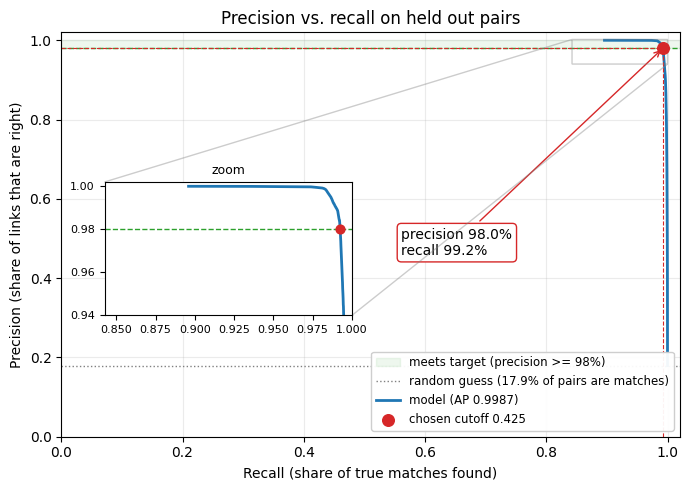

In [18]:
#the point I picked, and the share of true matches (what a random guess would score)
at_cut = curve.loc[(curve['cutoff'] - CUTOFF).abs().idxmin()]
baseline = curve['precision'].iloc[-1]

fig, ax = plt.subplots(figsize=(7, 5))
ax.axhspan(PRECISION_TARGET, 1.0, color='tab:green', alpha=0.08, label=f'meets target (precision >= {PRECISION_TARGET:.0%})')
ax.axhline(PRECISION_TARGET, color='tab:green', ls='--', lw=1)
ax.axhline(baseline, color='grey', ls=':', lw=1, label=f'random guess ({baseline:.1%} of pairs are matches)')
ax.plot(curve['recall'], curve['precision'], color='tab:blue', lw=2, label=f'model (AP {ap:.4f})')

#chosen cutoff, with dashed guides down to each axis
ax.scatter(at_cut['recall'], at_cut['precision'], s=70, color='tab:red', zorder=5, label=f'chosen cutoff {CUTOFF:.3f}')
ax.plot([at_cut['recall']] * 2, [0, at_cut['precision']], color='tab:red', ls='--', lw=0.8)
ax.plot([0, at_cut['recall']], [at_cut['precision']] * 2, color='tab:red', ls='--', lw=0.8)
ax.annotate(f"precision {pm['precision']:.1%}\nrecall {pm['recall']:.1%}",
            xy=(at_cut['recall'], at_cut['precision']), xytext=(0.55, 0.45), textcoords='axes fraction',
            arrowprops=dict(arrowstyle='->', color='tab:red'), fontsize=10,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='tab:red'))

#zoom into the top right corner, where the trade off actually happens
inset = ax.inset_axes([0.07, 0.30, 0.40, 0.33])
inset.plot(curve['recall'], curve['precision'], color='tab:blue', lw=2)
inset.axhline(PRECISION_TARGET, color='tab:green', ls='--', lw=1)
inset.scatter(at_cut['recall'], at_cut['precision'], s=40, color='tab:red', zorder=5)
inset.set_xlim(max(at_cut['recall'] - 0.15, 0), 1.0)
inset.set_ylim(PRECISION_TARGET - 0.04, 1.002)
inset.set_title('zoom', fontsize=9); inset.tick_params(labelsize=8)
ax.indicate_inset_zoom(inset, edgecolor='grey', alpha=0.4)

ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.set_xlabel('Recall (share of true matches found)'); ax.set_ylabel('Precision (share of links that are right)')
ax.set_title('Precision vs. recall on held out pairs')
ax.legend(loc='lower right', fontsize=8.5, framealpha=0.95)
ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig('images/precision_recall.png', dpi=150); plt.show()

**Result:**
* Average precision 0.9987, against a random baseline of 17.9%, so the model separates matches from non-matches almost perfectly.
* At cutoff 0.425, precision is 98.0% and recall is 99.2% on held out pairs, so the 98% precision target is met.
End to end recall is about 98.4% (99.1% kept by blocking x 99.2% found by the model).
* The curve starts at about 90% recall with 100% precision: the highest-scoring pairs alone already capture 9 in 10 true matches without a single error. Precision stays near 100% until about 97.5% recall, then drops quickly.

**Takeaway:**
* Most matches are easy, and a small hard tail is what limits recall. Pairs where name, DOB and a contact token all agree score near 1. The last 1 to 2% are records with typos in several fields, a move, or missing contact data, and pushing recall past 99.2% would cost precision fast. The error analysis in section 13 shows what those pairs look like.
* The cutoff lands close to v1’s 0.412 at 0.425, so the decision rule is stable even though the data is 200x bigger and now includes hashed contact data.
* 98% precision still means about 2 in 100 links are wrong. Clustering can amplify those (Test 3), which is why I check errors at the cluster level and not just pair metrics.
* Synthetic data is easier than real data. I set the error rates myself, so on real customer data I’d expect a lower curve and would set the cutoff with a manual review sample.

## 8. Test 3: Clustering and cluster level errors

**Goal:** turn matched pairs into one ID per person, and measure errors on the final clusters, since that's what downstream teams actually use.

### 8.1 Connected components in Spark
Records are nodes and matched pairs (score at or above the cutoff) are edges. Every connected group gets one `cluster_id`.

How it works: each record starts with its own ID as its label, then keeps taking the smallest label among its neighbors until nothing changes. It takes one round per hop across the widest cluster, so if the number of rounds suddenly jumps, that's already a sign of chaining. In production I'd swap in `GraphFrames.connectedComponents()`, which gives the same output and is built for billions of edges.

In [19]:
def connected_components(nodes, edges, max_iter=50):
    # nodes: (rec_id), edges: (src, dst). Returns (rec_id, cluster_id)
    e = edges.unionByName(edges.select(F.col('dst').alias('src'), F.col('src').alias('dst'))).distinct().cache()
    labels = nodes.select('rec_id', F.col('rec_id').alias('cluster_id')).localCheckpoint()
    for i in range(1, max_iter + 1):
        from_neighbors = (e.join(labels.withColumnRenamed('rec_id', 'src'), 'src')
                           .select(F.col('dst').alias('rec_id'), 'cluster_id'))
        new = (labels.unionByName(from_neighbors).groupBy('rec_id')
               .agg(F.min('cluster_id').alias('cluster_id')).localCheckpoint())   # checkpoint keeps the plan short
        changed = (new.alias('n').join(labels.alias('o'), 'rec_id')
                   .where(F.col('n.cluster_id') != F.col('o.cluster_id')).count())
        labels = new
        if changed == 0:
            print(f'converged in {i} rounds')
            break
    e.unpersist()
    return labels

def resolve(scored, cutoff):
    edges = scored.where(F.col('score') >= cutoff).select(F.col('id_l').alias('src'), F.col('id_r').alias('dst'))
    return connected_components(recs.select('rec_id'), edges).join(gt, 'rec_id')

In [20]:
%%time
resolved = resolve(scored, CUTOFF).cache()
log_metric('resolved clusters', resolved.select('cluster_id').distinct().count())

converged in 7 rounds
resolved clusters: 392231
CPU times: user 141 ms, sys: 16.4 ms, total: 157 ms
Wall time: 1min 50s


### 8.2 Cluster level metrics
Pair metrics count wrong links. Cluster metrics count wrong IDs, which is what the business sees.

| Metric | Definition | Error type |
|---|---|---|
| Over merged clusters | clusters with 2 or more true people | false merge (privacy risk) |
| Excess people absorbed | total of (true people in the cluster minus 1) | how big the over merge is |
| Split people | true people spread over 2 or more clusters | missed match |
| Excess fragments | total of (clusters per person minus 1) | how big the under merge is |
| Exact reconstruction | the person's records form exactly one cluster with nobody else | correct |
| B cubed precision / recall | for each record: share of its cluster that is the same person / share of its person found in its cluster | standard clustering metric, weighted by record |

I also put each person into one bucket: **exact**, **under merged only**, **over merged only**, or **both** (split, and one piece merged with someone else).

In [21]:
#res: (rec_id, cluster_id, true_person_id) -> summary dict, cluster table, person table
def cluster_eval(res):
    cells = res.groupBy('cluster_id', 'true_person_id').agg(F.count('*').alias('overlap'))
    clusters = cells.groupBy('cluster_id').agg(F.count('*').alias('n_people'), F.sum('overlap').alias('size'))
    persons = cells.groupBy('true_person_id').agg(F.count('*').alias('n_clusters'), F.sum('overlap').alias('size'))

    #a person counts as over merged if any cluster holding their records also holds someone else
    person_over = (cells.join(clusters.select('cluster_id', 'n_people'), 'cluster_id')
                   .groupBy('true_person_id').agg((F.max('n_people') > 1).alias('over')))
    persons = (persons.join(person_over, 'true_person_id')
               .withColumn('under', F.col('n_clusters') > 1)
               .withColumn('status', F.when(~F.col('over') & ~F.col('under'), 'exact')
                                      .when(F.col('under') & ~F.col('over'), 'under merged only')
                                      .when(F.col('over') & ~F.col('under'), 'over merged only')
                                      .otherwise('both')))

    bc = (cells.join(clusters.select('cluster_id', F.col('size').alias('csize')), 'cluster_id')
               .join(persons.select('true_person_id', F.col('size').alias('psize')), 'true_person_id')
               .agg(F.sum(F.pow(F.col('overlap'), 2) / F.col('csize')).alias('bp'),
                    F.sum(F.pow(F.col('overlap'), 2) / F.col('psize')).alias('br'),
                    F.sum('overlap').alias('n')).first())
    c = clusters.agg(F.count('*').alias('clusters'),
                     F.sum((F.col('n_people') > 1).cast('int')).alias('over_clusters'),
                     F.sum(F.col('n_people') - 1).alias('excess_people')).first()
    p = persons.agg(F.count('*').alias('people'),
                    F.sum(F.col('under').cast('int')).alias('split_people'),
                    F.sum(F.col('n_clusters') - 1).alias('excess_fragments')).first()
    status = {r['status']: r['count'] for r in persons.groupBy('status').count().collect()}

    bp, br = bc['bp'] / bc['n'], bc['br'] / bc['n']
    summary = {
        'resolved clusters': c['clusters'], 'true people': p['people'],
        'over merged clusters': c['over_clusters'], 'excess people absorbed': c['excess_people'],
        'split people': p['split_people'], 'excess fragments': p['excess_fragments'],
        'exact reconstruction rate': round(status.get('exact', 0) / p['people'], 4),
        'people exact': status.get('exact', 0),
        'people under merged only': status.get('under merged only', 0),
        'people over merged only': status.get('over merged only', 0),
        'people both': status.get('both', 0),
        'B cubed precision': round(bp, 4), 'B cubed recall': round(br, 4),
        'B cubed F1': round(2 * bp * br / (bp + br), 4),
    }
    return summary, clusters, persons

In [22]:
%%time
cl_summary, clusters_df, persons_df = cluster_eval(resolved)
for k, v in cl_summary.items():
    log_metric(f'cluster: {k}', v)

cluster: resolved clusters: 392231
cluster: true people: 400000
cluster: over merged clusters: 9686
cluster: excess people absorbed: 10364
cluster: split people: 2585
cluster: excess fragments: 2595
cluster: exact reconstruction rate: 0.9437
cluster: people exact: 377491
cluster: people under merged only: 2460
cluster: people over merged only: 19924
cluster: people both: 125
cluster: B cubed precision: 0.9738
cluster: B cubed recall: 0.9966
cluster: B cubed F1: 0.9851
CPU times: user 101 ms, sys: 13.1 ms, total: 114 ms
Wall time: 59.8 s


# **Result:**

* 94.4% of people were rebuilt exactly: all their records in one ID, with nobody else in it.
* Over-merges: 9,686 clusters hold more than one real person. They absorbed 10,364 extra people, about 1.07 per cluster, so nearly all of them are two people merged, not big chains. In total, 5.0% of people (20,049) share an ID with someone else.
* Splits: only 2,585 people (0.65%) are spread over more than one ID, and almost always into exactly 2 pieces (2,595 extra fragments).
* Over-merges affect about 8x more people than splits (20,049 vs. 2,585).
* B cubed precision 0.974 vs. recall 0.997. Recall is almost perfect; precision is where the errors are.

**Takeaway:**

* 98% pair precision became 97.4% at the record level, and 5% of people end up in a shared ID. Because clustering is transitive, every wrong link pulls in all of the other person’s records. That’s why I evaluate at the cluster level: the pair metric looked fine, but the customer-level view shows the real exposure.
* Two-person merges point to households: family members sharing a surname, address and sometimes a landline.

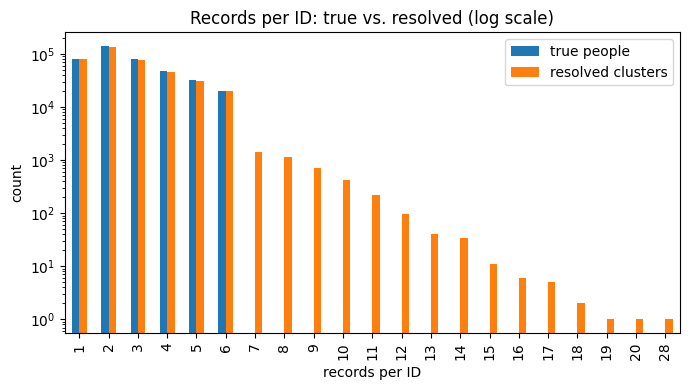

exact                94.37 %
under merged only     0.62 %
over merged only      4.98 %
both                  0.03 %
dtype: object


In [23]:
# records per ID: true vs resolved. A tail of big resolved clusters means chaining
true_sizes = persons_df.groupBy('size').count().toPandas().set_index('size')['count']
res_sizes = clusters_df.groupBy('size').count().toPandas().set_index('size')['count']
sizes = pd.DataFrame({'true people': true_sizes, 'resolved clusters': res_sizes}).fillna(0).astype(int).sort_index()
ax = sizes.plot(kind='bar', figsize=(7, 4), logy=True, title='Records per ID: true vs. resolved (log scale)')
ax.set_xlabel('records per ID'); ax.set_ylabel('count')
plt.tight_layout(); plt.savefig('images/cluster_sizes.png', dpi=150); plt.show()

status = pd.Series({k.replace('people ', ''): v for k, v in cl_summary.items() if k.startswith('people ')})
print((status / status.sum() * 100).round(2).astype(str) + ' %')

### 8.3 Where over merges come from: direct false links vs. chaining
Connected components are transitive, so one wrong link between two people pulls all of their records into one cluster. I count the false links (matched pairs from different people), group them by likely cause, and compare with the number of wrong record pairs after clustering. That ratio is the **chaining amplification**: how much damage each bad link does once it's clustered.

In [24]:
matched = scored.where(F.col('score') >= CUTOFF)
false_edges = (matched.where(F.col('label') == 0)
               .join(features.select('id_l', 'id_r', 'surname_jw', 'full_address_tsr', 'phone_h_eq', 'email_h_eq'),
                     ['id_l', 'id_r']))
cause = (F.when((F.col('surname_jw') >= 0.9) & (F.col('full_address_tsr') >= 0.9), 'same household (surname + address)')
          .when(F.col('phone_h_eq') == 1, 'shared phone')
          .when(F.col('email_h_eq') == 1, 'shared email')
          .otherwise('other (similar name/DOB, different person)'))
false_by_cause = false_edges.groupBy(cause.alias('cause')).count().toPandas().sort_values('count', ascending=False)
n_false_edges = int(false_by_cause['count'].sum())

# wrong record pairs after clustering = pairs in the same cluster from different people
cells = resolved.groupBy('cluster_id', 'true_person_id').agg(F.count('*').alias('k'))
wrong_pairs = (cells.groupBy('cluster_id').agg(F.sum('k').alias('n'), F.sum(F.pow(F.col('k'), 2)).alias('sq'))
               .agg(F.sum((F.pow(F.col('n'), 2) - F.col('sq')) / 2)).first()[0] or 0)

log_metric('false links (matched pairs, all data)', n_false_edges)
log_metric('wrong record pairs after clustering', int(wrong_pairs))
log_metric('chaining amplification', round(wrong_pairs / max(n_false_edges, 1), 2))
false_by_cause

false links (matched pairs, all data): 25769
wrong record pairs after clustering: 102454
chaining amplification: 3.98


,cause,count
2,same household (surname + address),19777
0,"other (similar name/DOB, different person)",5167
3,shared phone,808
1,shared email,17


**Result:** 25,769 false links became 102,454 wrong record pairs after clustering, a chaining amplification of 3.98. 77% of false links were same household pairs (surname + address), 20% lookalikes (similar name and DOB), 3% shared phone only, and almost none shared email. Households are the problem to fix, and the top 50 false links below are all family members at the same address.

In [25]:
#look at false links samples one by one:
  #pairs the model linked that are really different people (synthetic data)
cols = ['given', 'surname', 'dob', 'full_address', 'email', 'phone', 'true_household_id']
l = recs.select(F.col('rec_id').alias('id_l'), *[F.col(c).alias(f'{c}_l') for c in cols])
r = recs.select(F.col('rec_id').alias('id_r'), *[F.col(c).alias(f'{c}_r') for c in cols])

top_false = (matched.where(F.col('label') == 0)
             .join(features.select('id_l', 'id_r', 'surname_jw', 'full_address_tsr', 'phone_h_eq', 'email_h_eq'),
                   ['id_l', 'id_r'])
             .withColumn('cause', cause)
             .orderBy(F.desc('score'))          #rank higher score mistakes first
             .limit(50)
             .join(l, 'id_l').join(r, 'id_r')
             .withColumn('same_household', F.col('true_household_id_l') == F.col('true_household_id_r'))
             .toPandas())

show = ['score', 'cause', 'same_household'] + [f'{c}_{s}' for c in cols[:-1] for s in 'lr']
pd.set_option('display.max_columns', None); pd.set_option('display.max_colwidth', 40)
top_false.sort_values('score', ascending=False)[show].round(3)

,score,cause,same_household,given_l,given_r,surname_l,surname_r,dob_l,dob_r,full_address_l,full_address_r,email_l,email_r,phone_l,phone_r
36,1.000,same household (surname + address),True,alisha,takeisha,waterlow,waterlow,19271211,19271111,104 kauper street greensborough,104 kauper street greensborough,None,takeishawaterlow42@comcast.net,0416004494,0416004494
0,1.000,same household (surname + address),True,alexander,alyssa,geue,geue,19471121,19471101,116 pavonia street kinglake central ...,116 pavonia street kinglake central ...,alexander.geue@gmail.com,None,0433068149,0433068149
3,1.000,same household (surname + address),True,alyssa,alexander,geue,geue,19471101,19471121,116 pavonia street kinglake central ...,116 pavonia street kinglake central ...,None,None,0433068149,0433068149
8,1.000,same household (surname + address),True,alyssa,alexander,geue,geue,19471101,19471121,116 pavonia street kinglake central ...,116 pavonia street kinglake central ...,None,alexander.geue@gmail.com,0433068149,0433068149
1,1.000,same household (surname + address),True,alyssa,alexander,geue,geue,19471101,19471121,116 pavonia street kinglake central ...,116 pavonia street kinglake central ...,alyssa.geue20@gmail.com,None,0433068149,0433068149
2,1.000,same household (surname + address),True,alyssa,alexander,geue,geue,19471101,19471121,116 pavonia street kinglake centxal ...,116 pavonia street kinglake central ...,alyssa.geue20@gmail.com,None,0433068149,0433068149
21,1.000,same household (surname + address),True,alyssa,alexander,geue,geue,19471101,19471121,116 pavonia street kinglake central ...,116 pavonia street kinglake central ...,None,alexander.7972@icloud.com,0433068149,0433068149
27,1.000,same household (surname + address),True,michaela,milie,homann,homann,19800303,19800303,284 shellshear place annandale,284 shellshear place annandale,mhomann.199944@gmail.com,millie.homann@gmail.com,0436768133,0436768133
26,1.000,same household (surname + address),True,michaela,milie,homann,homann,19800303,19800303,284 shellshear place annandale,284 shellshear place annandale,mhomann.199944@gmail.com,millie.homann@gmail.com,0436768133,0436768133
9,0.999,same household (surname + address),True,michaela,millie,homann,homann,19800303,19800303,284 shellshear place annandale,284 shellshear place annandale,mhomann.199944@gmail.com,millie.homann@gmail.com,0436768133,0436768133


### 8.4 Cutoff vs. cluster errors
The cutoff was picked on pair precision. At the cluster level the real trade off is over merged clusters vs. split people, so I rerun clustering at a few cutoffs. This is the table I'd bring to stakeholders to set the cutoff on the outcome they actually care about.

converged in 8 rounds
converged in 7 rounds
converged in 7 rounds
converged in 5 rounds
converged in 4 rounds
converged in 4 rounds
converged in 4 rounds


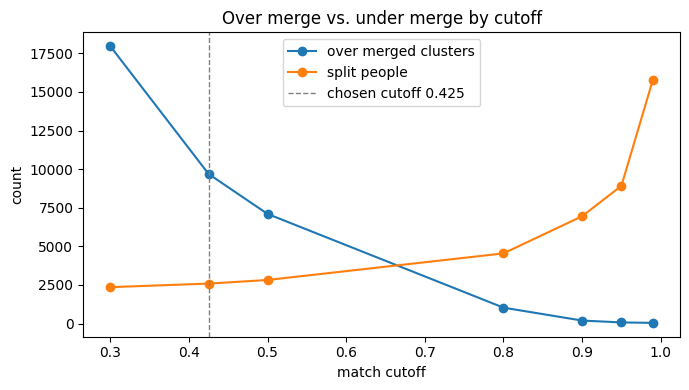

CPU times: user 1.68 s, sys: 317 ms, total: 2 s
Wall time: 15min 49s


,cutoff,over merged clusters,excess people absorbed,split people,excess fragments,exact reconstruction rate,B cubed precision,B cubed recall,B cubed F1
0,0.300,17962,19892,2354,2364,0.9001,0.9513,0.9969,0.9736
1,0.425,9686,10364,2585,2595,0.9437,0.9738,0.9966,0.9851
2,0.500,7097,7514,2819,2829,0.9567,0.9806,0.9963,0.9884
3,0.800,1027,1038,4541,4575,0.9835,0.9973,0.9941,0.9957
4,0.900,191,191,6947,7009,0.9817,0.9995,0.9909,0.9952
5,0.950,70,70,8918,9018,0.9774,0.9998,0.9883,0.9940
6,0.990,40,40,15780,16116,0.9604,0.9999,0.9792,0.9894


In [26]:
%%time
sweep_rows = []
for cut in sorted({0.3, 0.5, round(CUTOFF, 3), 0.8, 0.9, 0.95, 0.99}):
    s, _, _ = cluster_eval(resolve(scored, cut))
    sweep_rows.append({'cutoff': cut, **{k: s[k] for k in [
        'over merged clusters', 'excess people absorbed', 'split people', 'excess fragments',
        'exact reconstruction rate', 'B cubed precision', 'B cubed recall', 'B cubed F1']}})
cluster_sweep = pd.DataFrame(sweep_rows)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cluster_sweep['cutoff'], cluster_sweep['over merged clusters'], marker='o', label='over merged clusters')
ax.plot(cluster_sweep['cutoff'], cluster_sweep['split people'], marker='o', label='split people')
ax.axvline(CUTOFF, color='grey', ls='--', lw=1, label=f'chosen cutoff {CUTOFF:.3f}')
ax.set_xlabel('match cutoff'); ax.set_ylabel('count'); ax.set_title('Over merge vs. under merge by cutoff')
ax.legend(); plt.tight_layout(); plt.savefig('images/cluster_tradeoff.png', dpi=150); plt.show()
cluster_sweep

In [27]:
# look at the 3 biggest clusters, the first place chaining shows up (synthetic data)
largest = [r['cluster_id'] for r in clusters_df.orderBy(F.desc('size')).limit(3).collect()]
(resolved.where(F.col('cluster_id').isin(largest))
 .join(recs.select('rec_id', 'given', 'surname', 'dob', 'full_address', 'phone'), 'rec_id')
 .orderBy('cluster_id', 'true_person_id').toPandas())

,rec_id,cluster_id,true_person_id,given,surname,dob,full_address,phone
0,67831,8438,42110,mia,verner,19370664,63 vallance place lazy acres the hum...,0488462681
1,494503,8438,42110,mia,verner,19370624,63 vallance place lazy acres the hum...,0488462681
2,634265,8438,42110,mia,harrington,19370624,63 vallance place lazy acres the hum...,None
3,648329,8438,42110,mia,verner,19370624,63 vallance place lazy acres the hum...,0488462681
4,436259,8438,42110,mia,verner,19370624,63 vallance place lazy acres,0488462681
...,...,...,...,...,...,...,...,...
62,624322,82838,313970,indyana,capurso,19670919,250 gollan street northzryde,0465013086
63,262115,82838,313970,indyana,capurso,19670919,250 brownless street dapto,None
64,82838,82838,313970,indyana,capurso,19670919,250 brownless street dapto,0465013086
65,480101,82838,313970,None,capurso,19670919,250 brownless street dapto,0465013086


Example (`cluster 8438)`: 4 people and 19 records chained by 3 wrong links: a household link (Hamish and Mia Verner share surname, address and phone), a lookalike link (Mia Verner and Micaela Hanigan share an exact DOB and similar first names), and a second lookalike (Micaela and Rachel Hanigan share a surname and a DOB one digit apart). Hamish and Rachel have nothing in common but still became one customer. The model adds up agreements instead of requiring them: two strong matches outweigh three clear mismatches. This is what the higher cutoff, an interaction feature or a tree model should fix.

**Result:**

* At the chosen cutoff 0.425 (picked for 98% pair precision): 9,686 over-merged clusters, 2,585 split people, 94.4% exact.
* At 0.80: over-merged clusters drop to 1,027 (down 89%), split people rise to 4,541, and exact reconstruction is the best of any cutoff at 98.35% (B cubed F1 0.9957, also the best).
* At 0.90: only 191 over-merged clusters, 6,947 split people, 98.2% exact.
* Above 0.9 the trade turns bad: at 0.99, over-merges are nearly gone (40), but splits jump to 15,780 and exact falls to 96.0%.
* The two lines cross at about 0.66. Over-merges fall steeply until about 0.8, while splits grow slowly until about 0.8 and then shoot up.

**Takeaway:**

* Moving from 0.425 to 0.8 fixes about 8,700 over-merges at the cost of about 2,000 extra splits, roughly 4 to 1 in our favor. About 16,000 more people come out exactly right (94.4% → 98.35%).
* Why the pair metric picked the wrong spot: pair precision treats every wrong link the same, but after clustering each one does about 4x damage. Most false links are family members with medium scores (0.43 to 0.8), so raising the cutoff removes them first.

Lesson: set the cutoff on the outcome the business uses (customer IDs), not on pair precision alone.
Next step: look at finer cutoff

In [28]:
%%time
# finer sweep between 0.6 and 0.9, skipping cutoffs already run above
SWEEP_COLS = ['over merged clusters', 'excess people absorbed', 'split people', 'excess fragments',
              'exact reconstruction rate', 'B cubed precision', 'B cubed recall', 'B cubed F1']
fine_cuts = [0.60, 0.65, 0.70, 0.75, 0.85]
done = set(cluster_sweep['cutoff'].round(3))

rows = []
for cut in fine_cuts:
    if round(cut, 3) in done:
        continue
    s, _, _ = cluster_eval(resolve(scored, cut))
    rows.append({'cutoff': cut, **{k: s[k] for k in SWEEP_COLS}})

cluster_sweep_all = (pd.concat([cluster_sweep, pd.DataFrame(rows)])
                     .sort_values('cutoff').reset_index(drop=True))
cluster_sweep_all

converged in 6 rounds
converged in 6 rounds
converged in 6 rounds
converged in 6 rounds
converged in 5 rounds
CPU times: user 855 ms, sys: 246 ms, total: 1.1 s
Wall time: 11min 14s


,cutoff,over merged clusters,excess people absorbed,split people,excess fragments,exact reconstruction rate,B cubed precision,B cubed recall,B cubed F1
0,0.300,17962,19892,2354,2364,0.9001,0.9513,0.9969,0.9736
1,0.425,9686,10364,2585,2595,0.9437,0.9738,0.9966,0.9851
2,0.500,7097,7514,2819,2829,0.9567,0.9806,0.9963,0.9884
3,0.600,4815,5047,3415,3428,0.9670,0.9867,0.9956,0.9911
4,0.650,3603,3729,3715,3733,0.9726,0.9902,0.9952,0.9927
5,0.700,2556,2629,3970,3994,0.9772,0.9930,0.9948,0.9939
6,0.750,1744,1784,4257,4284,0.9806,0.9952,0.9945,0.9948
7,0.800,1027,1038,4541,4575,0.9835,0.9973,0.9941,0.9957
8,0.850,518,519,5052,5092,0.9848,0.9987,0.9934,0.9960
9,0.900,191,191,6947,7009,0.9817,0.9995,0.9909,0.9952


# **Result:**

* Exact reconstruction peaks at 0.85 (98.48%) and sits on a flat plateau from 0.75 to 0.90 (98.06% to 98.48%). Any cutoff in that range is close to optimal, so the decision isn’t sensitive to the exact number.
* From the pair cutoff (0.425) to 0.85:

1.   over-merged clusters: 9,686 → 518 (down 95%)
2.   split people: 2,585 → 5,052 (up about 2,500)
3.   exact reconstruction: 94.37% → 98.48%, about 16,400 more people rebuilt exactly
4.   B cubed precision 0.9738 → 0.9987, recall 0.9966 → 0.9934

* 0.85 is where the trade evens out. From 0.80 to 0.85, about 509 fewer merges cost about 511 more splits, an even swap. From 0.85 to 0.90, 327 fewer merges cost about 1,900 more splits, which isn’t worth it.
* The remaining over-merges at 0.85 are all small: 518 clusters absorbed 519 extra people, so they’re almost all two people, with no chains left.

**Decision:**
cluster cutoff 0.85. The pair rule picked 0.425 (98% pair precision), but at the customer level that left 9,686 over-merged clusters, because each wrong link pulls in the other person’s records. Sweeping cutoffs on cluster results, 0.85 gives the best exact reconstruction (98.48% vs. 94.37%) and cuts over-merged clusters by 95% (9,686 → 518), for about 2,500 more split people. Results are flat from 0.75 to 0.90, so the choice is robust. Past 0.85, each merge avoided costs about 6 extra splits. I use 0.85 for the final customer IDs and the tests that follow.

## 9. Test 4: Privacy, raw vs. hashed

**Goal:** if email and phone can only be used as salted tokens (exact match only, no fuzzy), how much accuracy do I give up? And what if every field had to be tokenized?

### 9.1 Does cleaning before hashing matter?
Quick check first. For true duplicate pairs where both records have an email (or phone), how often do the tokens match if I hash the raw value vs. the cleaned value?

In [29]:
def token_agreement(tok):
    l = recs.select(F.col('rec_id').alias('id_l'), F.col(tok).alias('a'))
    r = recs.select(F.col('rec_id').alias('id_r'), F.col(tok).alias('b'))
    j = true_pairs.join(l, 'id_l').join(r, 'id_r').where(F.col('a').isNotNull() & F.col('b').isNotNull())
    return j.agg(F.avg((F.col('a') == F.col('b')).cast('double'))).first()[0]

norm_check = pd.DataFrame({
    'identifier': ['email', 'phone'],
    'token match rate (hash raw value)': [token_agreement('email_h_raw'), token_agreement('phone_h_raw')],
    'token match rate (clean, then hash)': [token_agreement('email_h'), token_agreement('phone_h')],
}).round(4)
log_metric('true pair email token match (cleaned)', float(norm_check.iloc[0, 2]))
log_metric('true pair phone token match (cleaned)', float(norm_check.iloc[1, 2]))
norm_check

true pair email token match (cleaned): 0.8266
true pair phone token match (cleaned): 0.8428


,identifier,token match rate (hash raw value),"token match rate (clean, then hash)"
0,email,0.6615,0.8266
1,phone,0.5289,0.8428


**Note:** After cleaning, 82.7% of true pairs with an email on both sides share the same email token, and 84.3% for phone. Hashing the raw values gives only 66.2% and 52.9%.
Cleaning before hashing recovers 16.5 points for email (case and space noise) and 31.4 points for phone (+61, spaces, dashes, brackets). Without cleaning, almost half of true phone pairs would not match.
The remaining ~16 to 17% are real changes (typos, new emails or numbers) that no exact token can catch.

### 9.2 Four variants, same everything except the features
All four use the same candidate pairs (blocking is hashed in every case), the same train/test split and the same cutoff rule. The only thing that changes is what the model gets to see.

| Variant | Raw PII used for matching | Email / phone |
|---|---|---|
| A | names, address, DOB | not used |
| B | names, address, DOB, email, phone | fuzzy (edit distance) |
| C | names, address, DOB | salted hash, exact match |
| D | none | salted hash on every field (plus Soundex, swapped name and partial DOB tokens) |

**What I look at:** B vs. C is the cost of hashing. C vs. A is what hashed contact data still adds. D is the cost of never touching raw PII.

In [48]:
%%time
privacy_rows = []
for name, cols in FEATURES.items():
    if name == MAIN:
        v_scored, v_ap, v_cut, v_pm, v_cl = scored, ap, CUTOFF, pm, cl_summary   # already done in Test 2 and 3
    else:
        _, v_scored = train_and_score(cols)
        v_scored = v_scored.cache()
        v_curve, v_ap = pr_curve(v_scored)
        v_cut = pick_cutoff(v_curve)
        v_pm = pair_metrics(v_scored, v_cut)
        v_cl, _, _ = cluster_eval(resolve(v_scored, v_cut))
        v_scored.unpersist()
    privacy_rows.append({
        'variant': name, 'average precision': round(v_ap, 4), 'cutoff': v_cut,
        'pair precision': v_pm['precision'], 'pair recall': v_pm['recall'],
        'end to end recall': round(metrics['blocking: pair completeness'] * v_pm['recall'], 4),
        'B cubed F1': v_cl['B cubed F1'], 'exact reconstruction': v_cl['exact reconstruction rate'],
        'over merged clusters': v_cl['over merged clusters'], 'split people': v_cl['split people'],
    })

privacy = pd.DataFrame(privacy_rows).set_index('variant')
privacy.to_csv('privacy_comparison.csv')
log_metric('privacy: recall lost by hashing email/phone (B minus C)',
           round(privacy.loc['B: raw contact (fuzzy)', 'end to end recall'] - privacy.loc[MAIN, 'end to end recall'], 4))
log_metric('privacy: recall added by hashed email/phone (C minus A)',
           round(privacy.loc[MAIN, 'end to end recall'] - privacy.loc['A: raw, no contact', 'end to end recall'], 4))
privacy

converged in 5 rounds
converged in 7 rounds
converged in 7 rounds
privacy: recall lost by hashing email/phone (B minus C): -0.006
privacy: recall added by hashed email/phone (C minus A): 0.0283
CPU times: user 845 ms, sys: 171 ms, total: 1.02 s
Wall time: 13min 41s


,average precision,cutoff,pair precision,pair recall,end to end recall,B cubed F1,exact reconstruction,over merged clusters,split people
variant,,,,,,,,,
"A: raw, no contact",0.9914,0.718,0.9802,0.9640,0.9553,0.9831,0.9314,7889,11941
B: raw contact (fuzzy),0.9983,0.615,0.9800,0.9865,0.9776,0.9862,0.9446,8881,4171
C: hashed contact,0.9987,0.425,0.9800,0.9925,0.9836,0.9851,0.9437,9686,2585
D: all hashed,0.9992,0.236,0.9808,0.9957,0.9867,0.9848,0.9455,9565,1918


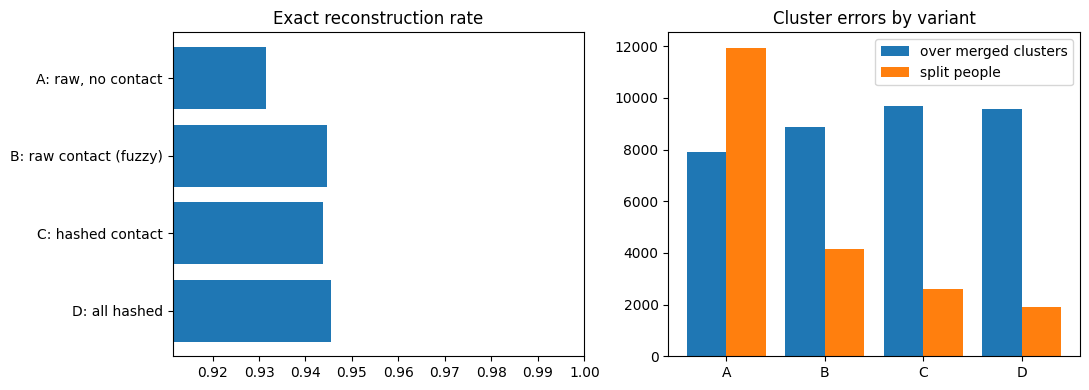

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = privacy.index.tolist()
axes[0].barh(labels, privacy['exact reconstruction'])
axes[0].set_xlim(privacy['exact reconstruction'].min() - 0.02, 1); axes[0].invert_yaxis()
axes[0].set_title('Exact reconstruction rate')
x = np.arange(len(labels))
axes[1].bar(x - 0.2, privacy['over merged clusters'], 0.4, label='over merged clusters')
axes[1].bar(x + 0.2, privacy['split people'], 0.4, label='split people')
axes[1].set_xticks(x); axes[1].set_xticklabels([l.split(':')[0] for l in labels]); axes[1].legend()
axes[1].set_title('Cluster errors by variant')
plt.tight_layout(); plt.savefig('images/privacy_comparison.png', dpi=150); plt.show()

**Result:** hashing email and phone cost no recall; it gained 0.6 points of end to end recall vs. raw fuzzy matching (98.4% vs. 97.8%, B vs. C), and it added 2.8 points over not using contact data at all (C vs. A), cutting split people from 11,941 to 2,585. Going fully hashed (D) raised exact reconstruction slightly, from 94.4% to 94.6%, with end to end recall of 98.7% and no raw PII used anywhere.

**Takeaway:** once fields are cleaned before hashing, tokenized contact data costs nothing here, so it’s an easy call. Exact token matches gave the linear model a cleaner signal than edit distance, which gives partial credit to different people with similar emails or phones. In D, Soundex, swapped-name and partial DOB tokens recovered most of the typo tolerance that names lose without fuzzy matching. The caveat is that my synthetic typos are simple one-character edits. On real data, nicknames and transliterations make fuzzy name matching more valuable, so I’d expect a small cost for full tokenization and would measure it on a review sample before relying on it.

**What hashing protects, and what it doesn't**

| | |
|---|---|
| Protects | stored match keys don't reveal any email or phone without the key; analysts and downstream jobs never see raw contact data |
| Doesn't protect | two records with the same token clearly share a value, so token tables still need access control. If the key leaks, low entropy fields like phone and DOB can be brute forced, so the key needs a secret manager and rotation |
| Next step | Bloom filter encoding of name bigrams (the standard approach in privacy preserving record linkage) would allow fuzzy matching on encoded names |

## 10. Test 5: Match confidence

**Goal:** turn the model score into a confidence I can actually explain: a link with confidence 0.9 should be right about 9 times out of 10. Then use it to split links into tiers.

**Why the raw score isn't a confidence:** I trained with balanced class weights, which tells the model matches and non matches are 50/50. In the candidate pairs they're not, so the raw score is pushed up. It ranks pairs well (that's what the cutoff uses), but "0.9" doesn't mean 90%.

**Setup:**
1. Split the test pairs in half. Calibrate on one half, check on the other, so the check is honest.
2. Platt scaling: a one feature logistic regression on the logit of the raw score. Simple, and easy to explain.
3. Check with a reliability table (average confidence vs. observed match rate per bin) and expected calibration error (ECE, the gap between the two, weighted by pairs).
4. Confidence tiers: **auto link** (0.95 and up), **review** (0.50 to 0.95), **no link** (below 0.50).
5. Confidence by evidence type: a shared email or phone token works like a deterministic link; names, address and DOB alone are probabilistic.

**What I look at:** ECE before vs. after, precision in each tier, review volume, and how confidence changes with the kind of evidence.

In [44]:
eps = 1e-6
clipped = F.least(F.greatest(F.col('score'), F.lit(eps)), F.lit(1 - eps))
platt_in = VectorAssembler(inputCols=['logit'], outputCol='pv').transform(
    scored.withColumn('logit', F.log(clipped / (1 - clipped)))
          .withColumn('half', F.abs(F.hash('id_l', 'id_r')) % 2))      # fixed split of the test pairs

platt = LogisticRegression(featuresCol='pv', labelCol='label', predictionCol='p_pred',
                           probabilityCol='p_prob', rawPredictionCol='p_raw')
platt = platt.fit(platt_in.where(F.col('is_test') & (F.col('half') == 0)))

confident = (platt.transform(platt_in)
             .withColumn('confidence', vector_to_array('p_prob')[1])
             .select('id_l', 'id_r', 'label', 'is_test', 'half', 'score', 'confidence')
             .cache())
check = confident.where(F.col('is_test') & (F.col('half') == 1))   # the half the calibration never saw

def reliability(df, col, bins=10):
    t = (df.withColumn('bin', F.least(F.floor(F.col(col) * bins), F.lit(bins - 1)))
           .groupBy('bin').agg(F.avg(col).alias('avg confidence'), F.avg('label').alias('observed match rate'),
                               F.count('*').alias('pairs'))
           .toPandas().sort_values('bin'))
    ece = float((t['pairs'] * (t['avg confidence'] - t['observed match rate']).abs()).sum() / t['pairs'].sum())
    return t.round(3), ece

rel_raw, ece_raw = reliability(check, 'score')
rel_cal, ece_cal = reliability(check, 'confidence')
log_metric('confidence: ECE raw score', round(ece_raw, 4))
log_metric('confidence: ECE calibrated', round(ece_cal, 4))
rel_cal

confidence: ECE raw score: 0.008
confidence: ECE calibrated: 0.0009


,bin,avg confidence,observed match rate,pairs
5,0,0.001,0.001,868810
6,1,0.138,0.058,4574
4,2,0.245,0.267,1694
7,3,0.346,0.399,1089
3,4,0.450,0.436,700
9,5,0.547,0.486,580
1,6,0.651,0.533,540
2,7,0.757,0.839,800
8,8,0.848,0.940,1435
0,9,0.999,1.000,186173


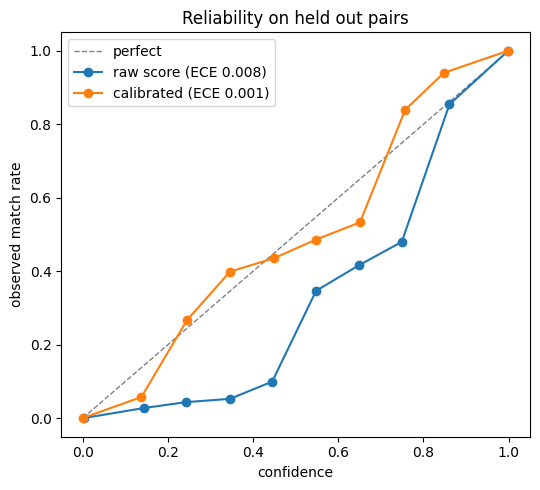

In [45]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color='grey', ls='--', lw=1, label='perfect')
ax.plot(rel_raw['avg confidence'], rel_raw['observed match rate'], marker='o', label=f'raw score (ECE {ece_raw:.3f})')
ax.plot(rel_cal['avg confidence'], rel_cal['observed match rate'], marker='o', label=f'calibrated (ECE {ece_cal:.3f})')
ax.set_xlabel('confidence'); ax.set_ylabel('observed match rate'); ax.set_title('Reliability on held out pairs')
ax.legend(); plt.tight_layout(); plt.savefig('images/reliability.png', dpi=150); plt.show()

`**Result:**` calibration cut ECE from 0.008 to 0.0009. 98.9% of pairs sit near 0 or 1 and are perfectly calibrated; in the uncertain middle (1% of pairs) confidence is off by about 7 points, overconfident around 0.6 to 0.7 and underconfident around 0.75 to 0.85. Overall ECE is flattered by the easy pairs, so I’d check calibration where decisions are made.

In [46]:
tier = (F.when(F.col('confidence') >= 0.95, '1 auto link (>= 0.95)')
         .when(F.col('confidence') >= 0.50, '2 review (0.50 to 0.95)')
         .otherwise('3 no link (< 0.50)'))

# volume on all candidate pairs, precision on the held out half
volume = confident.groupBy(tier.alias('tier')).agg(F.count('*').alias('pairs, all data'))
quality = check.groupBy(tier.alias('tier')).agg(F.round(F.avg('label'), 4).alias('precision (held out)'),
                                                F.round(F.avg('confidence'), 4).alias('avg confidence'))
tiers = volume.join(quality, 'tier').orderBy('tier').toPandas()
tiers['share of pairs'] = (tiers['pairs, all data'] / tiers['pairs, all data'].sum()).round(4)
log_metric('confidence: pairs sent to review', int(tiers.loc[tiers['tier'].str.startswith('2'), 'pairs, all data'].sum()))
tiers

confidence: pairs sent to review: 29000


,tier,"pairs, all data",precision (held out),avg confidence,share of pairs
0,1 auto link (>= 0.95),1231134,0.9998,0.9995,0.1735
1,2 review (0.50 to 0.95),29000,0.8183,0.7816,0.0041
2,3 no link (< 0.50),5836322,0.0031,0.0033,0.8224


**Result:** 17% of candidate pairs can be linked automatically with 99.98% accuracy. Only 29,000 pairs (0.4%) need a person to look at them, and 4 out of 5 of those turn out to be real matches. Everything else can be safely ignored.

In [47]:
# deterministic style evidence (shared token) vs probabilistic (names, address, DOB only)
evidence = (F.when((F.col('email_h_eq') == 1) & (F.col('phone_h_eq') == 1), 'email and phone token')
             .when(F.col('email_h_eq') == 1, 'email token only')
             .when(F.col('phone_h_eq') == 1, 'phone token only')
             .otherwise('no shared token (probabilistic)'))
(check.join(features.select('id_l', 'id_r', 'email_h_eq', 'phone_h_eq'), ['id_l', 'id_r'])
      .groupBy(evidence.alias('evidence'))
      .agg(F.count('*').alias('pairs'),
           F.round(F.avg('confidence'), 3).alias('avg confidence'),
           F.round(F.avg('label'), 3).alias('observed match rate'),
           F.round(F.avg((F.col('confidence') >= 0.95).cast('double')), 3).alias('share auto linked'))
      .orderBy(F.desc('avg confidence')).toPandas())

,evidence,pairs,avg confidence,observed match rate,share auto linked
0,email and phone token,92603,1.000,1.000,0.999
1,email token only,44409,0.998,1.000,0.995
2,phone token only,60748,0.602,0.592,0.542
3,no shared token (probabilistic),868635,0.021,0.021,0.018


Note: a shared email token alone is almost always right (observed 100%, 99.5% auto linked), but a shared phone token alone is right only 59% of the time, because households share landlines. That’s why the phone weight is a third of the email weight, and why a shared identifier still needs a confidence.

## 11. Test 6: Graph stability over time

**Goal:** show that IDs stay stable when the graph is rebuilt, and that when they do change, it's for a good reason.

In production the graph gets rebuilt on a schedule. If a person's ID changes every run, frequency caps, measurement joins and reports all break, even when nothing about the person changed.

**Setup: two realistic reasons for a rebuild**
1. **Scenario A, next month's data arrives.** About 5% of existing people show up again with new records, plus new people. I only block and score pairs that involve a new record (incremental run), keep last month's edges, and recluster everything.
2. **Scenario B, model refresh, same data.** I retrain on a different train/test split and pick a new cutoff. Nothing about the people changed, so every ID change here is churn caused by the method itself.

**Stable ID mapping:** connected components labels each cluster with its smallest rec_id, which can change when clusters merge. So I map each new cluster to the old ID it overlaps most. If an old cluster splits, the biggest piece keeps the ID and the rest get new ones.

**What I look at:** for records in both runs, % whose ID changed (raw cluster label vs. stable ID), the number of splits and merges, and whether each change was a **fix** (joined pieces of the same person, or split an over merge) or **new damage**.

In [52]:
def stable_ids(prev, curr):
    # prev: (rec_id, stable_id) from last run; curr: (rec_id, cluster_id) from this run -> (rec_id, cluster_id, stable_id)
    overlap = curr.join(prev, 'rec_id').groupBy('cluster_id', 'stable_id').count()
    # each new cluster claims the old ID it overlaps most
    best = (overlap.withColumn('r', F.row_number().over(
                Window.partitionBy('cluster_id').orderBy(F.desc('count'), 'stable_id')))
            .where('r = 1'))
    # if an old cluster split, only the biggest piece keeps its ID
    keep = (best.withColumn('r', F.row_number().over(
                Window.partitionBy('stable_id').orderBy(F.desc('count'), 'cluster_id')))
            .where('r = 1').select('cluster_id', 'stable_id'))
    return (curr.join(keep, 'cluster_id', 'left')
                .withColumn('stable_id', F.coalesce('stable_id', F.concat(F.lit('N'), F.col('cluster_id').cast('string'))))
                .select('rec_id', 'cluster_id', 'stable_id'))

def compare_runs(prev, curr):
    # prev / curr: (rec_id, cluster_id, stable_id, true_person_id); only records present in both runs count
    j = (prev.alias('p').join(curr.alias('c'), 'rec_id')
         .select('rec_id', F.col('p.cluster_id').alias('pc'), F.col('p.stable_id').alias('ps'),
                 F.col('c.cluster_id').alias('cc'), F.col('c.stable_id').alias('cs'),
                 F.col('p.true_person_id').alias('person'))
         .cache())
    n = j.count()
    splits = j.groupBy('ps').agg(F.countDistinct('cc').alias('pieces'), F.countDistinct('person').alias('people')).where('pieces > 1')
    merges = j.groupBy('cc').agg(F.countDistinct('ps').alias('pieces'), F.countDistinct('person').alias('people')).where('pieces > 1')
    out = {
        'records in both runs': n,
        'raw cluster label changed %': round(j.where('pc != cc').count() / n * 100, 3),
        'stable ID changed %': round(j.where('ps != cs').count() / n * 100, 3),
        'splits': splits.count(),
        'splits that fixed an over merge': splits.where('people > 1').count(),
        'merges': merges.count(),
        'merges that joined one person (fix)': merges.where('people = 1').count(),
        'merges that joined different people (damage)': merges.where('people > 1').count(),
    }
    j.unpersist()
    return out

run1 = resolved.withColumn('stable_id', F.col('cluster_id').cast('string')).cache()   # last month's IDs

### 11.1 Scenario A: next month's data

In [53]:
%%time
org_pd = pd.read_parquet('raw_records.parquet')
org_pd = org_pd[org_pd['record_type'] == 'org']
batch_pd = generate_batch(org_pd, vocab, frac_existing=0.05, n_new_people=N_PEOPLE // 20,
                          person_offset=N_PEOPLE, start_rec_id=n_records, seed=7)
batch_pd[['true_person_id', 'true_household_id']] = batch_pd[['true_person_id', 'true_household_id']].astype('int64')
batch_str = [c for c in batch_pd.columns if c not in ('rec_id', 'true_person_id', 'true_household_id')]
batch_pd[batch_str] = batch_pd[batch_str].astype('string')
batch_pd.to_parquet('batch2_records.parquet', index=False)
del org_pd, batch_pd

NEW_START = n_records      # every rec_id from here up is new this month
prepare(spark.read.parquet('batch2_records.parquet')).drop('email_raw', 'phone_raw') \
    .write.mode('overwrite').parquet(f'{OUT}/records_batch2')
recs_all = recs.unionByName(spark.read.parquet(f'{OUT}/records_batch2')).cache()
log_metric('stability: new records this month', recs_all.count() - n_records)

# incremental blocking: same passes, but only keep pairs that involve a new record (id_r is the larger id)
new_cands = None
for k in BLOCK_PASSES:
    p, _ = block_pairs(recs_all, k)
    p = p.where(F.col('id_r') >= NEW_START).select('id_l', 'id_r')
    new_cands = p if new_cands is None else new_cands.unionByName(p)
new_cands = new_cands.distinct()

# score the new pairs with last month's model and cutoff (no retraining)
new_feats = pair_features(new_cands, recs_all)
new_scored = (model.transform(VectorAssembler(inputCols=FEATURES[MAIN], outputCol='fv').transform(new_feats))
              .withColumn('score', vector_to_array('probability')[1])
              .select('id_l', 'id_r', 'label', 'score'))

edges2 = (scored.where(F.col('score') >= CUTOFF).select(F.col('id_l').alias('src'), F.col('id_r').alias('dst'))
          .unionByName(new_scored.where(F.col('score') >= CUTOFF).select(F.col('id_l').alias('src'), F.col('id_r').alias('dst'))))
gt_all = recs_all.select('rec_id', 'true_person_id')
clusters2 = connected_components(recs_all.select('rec_id'), edges2)
run2 = stable_ids(run1.select('rec_id', 'stable_id'), clusters2).join(gt_all, 'rec_id').cache()

stability_a = compare_runs(run1, run2)
for k, v in stability_a.items():
    log_metric(f'stability A: {k}', v)

stability: new records this month: 52811
converged in 7 rounds
stability A: records in both runs: 1070421
stability A: raw cluster label changed %: 0.048
stability A: stable ID changed %: 0.038
stability A: splits: 0
stability A: splits that fixed an over merge: 0
stability A: merges: 201
stability A: merges that joined one person (fix): 2
stability A: merges that joined different people (damage): 199
CPU times: user 6.35 s, sys: 1.01 s, total: 7.36 s
Wall time: 12min 51s


**Note:** in Scenario A I keep last month's edges, so old clusters can only merge, never split. Every change is either a new record connecting two pieces of the same person (a fix of an old split) or a new record bridging two different people (damage). Without the stable ID mapping, the raw cluster label would also change for records that were simply joined by a new record with no real change in who they are.

**Result:** 52,811 new records arrived and only 0.038% of existing records changed stable ID (0.048% for the raw label). But of 201 merges, 199 joined different people and only 2 fixed a split. New records from one family member link to another member’s cluster, the same household problem as Test 3, now arriving month by month. This run uses the loose pair cutoff, so the stricter cutoff should cut it.

### 11.2 Scenario B: model refresh on the same data

In [38]:
%%time
refresh_data = features.withColumn('is_test', F.rand(RANDOM_STATE + 1) < 0.3)   # different split, same pairs
_, scored_b = train_and_score(FEATURES[MAIN], data=refresh_data)
scored_b = scored_b.cache()
curve_b, _ = pr_curve(scored_b)
cutoff_b = pick_cutoff(curve_b)
log_metric('stability B: refreshed cutoff', cutoff_b)

clusters_b = connected_components(recs.select('rec_id'),
                                  scored_b.where(F.col('score') >= cutoff_b)
                                          .select(F.col('id_l').alias('src'), F.col('id_r').alias('dst')))
run_b = stable_ids(run1.select('rec_id', 'stable_id'), clusters_b).join(gt, 'rec_id')
stability_b = compare_runs(run1, run_b)
for k, v in stability_b.items():
    log_metric(f'stability B: {k}', v)
scored_b.unpersist()

pd.DataFrame({'A: next month data': stability_a, 'B: model refresh': stability_b})

stability B: refreshed cutoff: 0.423
converged in 7 rounds
stability B: records in both runs: 1070421
stability B: raw cluster label changed %: 0.023
stability B: stable ID changed %: 0.018
stability B: splits: 53
stability B: splits that fixed an over merge: 52
stability B: merges: 40
stability B: merges that joined one person (fix): 3
stability B: merges that joined different people (damage): 37
CPU times: user 253 ms, sys: 54 ms, total: 307 ms
Wall time: 4min 54s


,A: next month data,B: model refresh
records in both runs,1070421.000,1070421.000
raw cluster label changed %,0.048,0.023
stable ID changed %,0.038,0.018
splits,0.000,53.000
splits that fixed an over merge,0.000,52.000
merges,201.000,40.000
merges that joined one person (fix),2.000,3.000
merges that joined different people (damage),199.000,37.000


**Result:** (Scenario B, model refresh on the same data):

* The refreshed model picked a cutoff of 0.423 (vs. 0.425), and 0.018% of records changed stable ID (about 190), half the churn of next month’s data.
* 53 splits, 52 of which broke up an existing over-merge (good).
* 40 merges, 37 of which joined different people (bad).
* Net effect: 52 wrong merges removed and 37 new ones created, so slightly better overall. But about 90 clusters changed with zero real-world change.

**Takeaway:** stable IDs need two things: a mapping step so harmless relabeling doesn't count as change, and a check on every model or cutoff change before it ships, because a refresh can move IDs with zero real world change. In production I'd track "stable ID changed %" and "merges that joined different people" every run and alert when either jumps. It's the same habit as running PSI on every new feed: if the output moved, I want to know why before anyone downstream sees it.

## 12. Test 7: Person vs. household

**Goal:** keep two levels of identity. People in one household (same address, often same surname, sometimes a shared landline) should get **different person IDs** but the **same household ID**.

This is where person matching gets hard. Two family members can share surname, address and phone, which is exactly why "same household" was a top cause of false links in Test 3.

**Setup:**
1. Start from the person clusters in Test 3.
2. Give each person one home address: the address (street number + street + postcode, as hashed tokens) seen most often across their records. Using the most common one stops an old address from a move chaining two households together.
3. People with the same home address form one household.
4. Guard rail: an address shared by more than `MAX_HOUSEHOLD` people is probably an apartment building, office or placeholder, so those people stay as single person households.
5. Compare with the true household from the generator (evaluation only).

**What I look at:** household B cubed precision and recall, and for real household members (different people, same household): % merged into one person by mistake, % kept as separate people **and** linked into one household (the goal), and % not linked.

In [39]:
MAX_HOUSEHOLD = 8

addr_key = F.when(F.col('street_no_h').isNotNull() & F.col('address1_h').isNotNull() & F.col('postcode_h').isNotNull(),
                  F.concat_ws('|', 'street_no_h', 'address1_h', 'postcode_h'))
person_addr = (resolved.join(recs.select('rec_id', addr_key.alias('addr')), 'rec_id')
               .where(F.col('addr').isNotNull())
               .groupBy('cluster_id', 'addr').count())
home = (person_addr.withColumn('r', F.row_number().over(
            Window.partitionBy('cluster_id').orderBy(F.desc('count'), 'addr')))
        .where('r = 1').select('cluster_id', 'addr'))

addr_size = home.groupBy('addr').agg(F.count('*').alias('people_at_addr'))
log_metric('household: addresses skipped by guard rail', addr_size.where(F.col('people_at_addr') > MAX_HOUSEHOLD).count())

person_hh = (home.join(addr_size, 'addr')
             .withColumn('household_id', F.when(F.col('people_at_addr') <= MAX_HOUSEHOLD, F.col('addr')))
             .select('cluster_id', 'household_id'))

hh = (resolved.join(person_hh, 'cluster_id', 'left')
      # people with no address, or at an oversized address, are their own household
      .withColumn('household_id', F.coalesce('household_id', F.concat(F.lit('P'), F.col('cluster_id').cast('string'))))
      .join(recs.select('rec_id', 'true_household_id'), 'rec_id')
      .cache())

hh_summary, _, _ = cluster_eval(hh.select('rec_id', F.col('household_id').alias('cluster_id'),
                                          F.col('true_household_id').alias('true_person_id')))
log_metric('household: resolved households', hh_summary['resolved clusters'])
log_metric('household: true households', hh_summary['true people'])
log_metric('household: B cubed precision', hh_summary['B cubed precision'])
log_metric('household: B cubed recall', hh_summary['B cubed recall'])
log_metric('household: exact reconstruction rate', hh_summary['exact reconstruction rate'])

household: addresses skipped by guard rail: 0
household: resolved households: 343938
household: true households: 340081
household: B cubed precision: 0.9915
household: B cubed recall: 0.9865
household: exact reconstruction rate: 0.9672


In [40]:
# each true person's main person ID and household ID (the one most of their records got)
def main_value(col):
    return (hh.groupBy('true_person_id', col).count()
              .withColumn('r', F.row_number().over(Window.partitionBy('true_person_id').orderBy(F.desc('count'), col)))
              .where('r = 1').select('true_person_id', col))

people = (main_value('cluster_id').join(main_value('household_id'), 'true_person_id')
          .join(hh.select('true_person_id', 'true_household_id').distinct(), 'true_person_id'))

# every pair of different people who really live together (same address, same surname by construction)
members = (people.alias('a').join(people.alias('b'), 'true_household_id')
           .where(F.col('a.true_person_id') < F.col('b.true_person_id')))
outcome = (F.when(F.col('a.cluster_id') == F.col('b.cluster_id'), '1 merged into one person (over merge)')
            .when(F.col('a.household_id') == F.col('b.household_id'), '2 separate people, same household (goal)')
            .otherwise('3 separate people, household not linked'))
member_outcomes = members.groupBy(outcome.alias('outcome')).count().orderBy('outcome').toPandas()
member_outcomes['share'] = (member_outcomes['count'] / member_outcomes['count'].sum()).round(4)
log_metric('household: member pairs kept separate and linked (%)',
           round(float(member_outcomes.loc[member_outcomes['outcome'].str.startswith('2'), 'share'].sum()) * 100, 2))
member_outcomes

household: member pairs kept separate and linked (%): 78.74


,outcome,count,share
0,1 merged into one person (over merge),8001,0.1227
1,"2 separate people, same household (g...",51346,0.7874
2,"3 separate people, household not linked",5864,0.0899


In [41]:
# one real household with 3 or more people: different person IDs, one household ID (synthetic data)
example_hh = (people.groupBy('true_household_id').count().where('count >= 3')
              .orderBy('true_household_id').first()['true_household_id'])
(hh.where(F.col('true_household_id') == example_hh)
   .join(recs.select('rec_id', 'given', 'surname', 'dob', 'full_address', 'phone'), 'rec_id')
   .select('true_person_id', 'cluster_id', 'household_id', 'given', 'surname', 'dob', 'full_address', 'phone')
   .orderBy('true_person_id').toPandas())

,true_person_id,cluster_id,household_id,given,surname,dob,full_address,phone
0,72,255523,8677bcf134acc3b453fa9a27556f91ee8fc7...,bayden,binns,19300208,363 benny place rosedale marsden,0458866839
1,72,255523,8677bcf134acc3b453fa9a27556f91ee8fc7...,bayden,binns,19300208,363 benny place rosedale marsden,0458866829
2,220940,151543,8677bcf134acc3b453fa9a27556f91ee8fc7...,madison,binns,19640201,benny place marsden,0495401841
3,220940,151543,8677bcf134acc3b453fa9a27556f91ee8fc7...,madison,binns,19640201,102 riordan street rosedale auburn,0495401841
4,220940,151543,8677bcf134acc3b453fa9a27556f91ee8fc7...,madison,binns,19640201,363 benny place rosedale marsden,0495401841
5,220940,151543,8677bcf134acc3b453fa9a27556f91ee8fc7...,madison,binns,19640201,364 benny place roysedale marsden,0495401841
6,220940,151543,8677bcf134acc3b453fa9a27556f91ee8fc7...,madiosn,binns,19640201,363 benny place rosedale marsden,0495401841
7,282072,443160,8677bcf134acc3b453fa9a27556f91ee8fc7...,nemesia,binns,19360105,363 benny place rosedale marsden,0427206097
8,282072,443160,8677bcf134acc3b453fa9a27556f91ee8fc7...,nemesia,binns,19360105,363 benny place rosedale marsden,0427206097


**Result:** household B cubed precision 0.9915 and recall 0.9865, with 96.7% of households rebuilt exactly (vs. 94.4% at the person level). Of the 65,211 real household member pairs, 78.7% were kept as separate people and linked into one household, 12.3% were wrongly merged into one person, and 9.0% weren't linked (mostly family members whose most common address differs from the rest of the family, after a move or because of address typos). Overall, 91% of family pairs ended up in the same household. The guard rail skipped no addresses, since the synthetic data has no apartment buildings or placeholder addresses.

**Takeaway:** separating the two levels gives each use its own ID: person IDs for frequency caps and person level matching, household IDs for reach and household targeting. It also gives the person model a way out on its hardest cases. When two people share surname, address and phone, the right answer is often "same household, not sure it's the same person", and that link can live at the household level instead of becoming a false merge. The 12.3% merged into one person come from the loose pair cutoff (0.425) and should mostly disappear at the cluster cutoff (0.85); the 9% not linked would need a most recent address rule or a second household signal like a shared landline. This mirrors what I did in AML, where I grouped accounts into both customers and households from KYC address, email and phone.

## 13. Error analysis (main model)
The headline numbers say how much error there is. The examples say why, and that decides what to fix next.

In [42]:
missed_by_blocking = n_true_pairs - int(candidates.agg(F.sum('label')).first()[0])
missed_below_cutoff = scored.where((F.col('label') == 1) & (F.col('score') < CUTOFF)).count()
false_merge_pairs = scored.where((F.col('label') == 0) & (F.col('score') >= CUTOFF)).count()
log_metric('missed matches: lost at blocking', missed_by_blocking)
log_metric('missed matches: scored below cutoff', missed_below_cutoff)
log_metric('false merges (pairs, all data)', false_merge_pairs)
log_metric('share of missed pairs lost at blocking',
           round(missed_by_blocking / max(missed_by_blocking + missed_below_cutoff, 1), 4))

def show_pairs(df, n=5):
    # both records of each pair side by side (synthetic data)
    cols = ['given', 'surname', 'dob', 'full_address', 'email', 'phone']
    l = recs.select(F.col('rec_id').alias('id_l'), *[F.col(c).alias(f'{c}_l') for c in cols])
    r = recs.select(F.col('rec_id').alias('id_r'), *[F.col(c).alias(f'{c}_r') for c in cols])
    out = df.limit(n).join(l, 'id_l').join(r, 'id_r').toPandas()
    return (out[['score'] + [f'{c}_{s}' for c in cols for s in 'lr']]
            .sort_values('score', ascending=False).round(3))

print('Missed matches that scored just under the cutoff:')
display(show_pairs(scored.where((F.col('label') == 1) & (F.col('score') < CUTOFF)).orderBy(F.desc('score'))))
print('False merges with the highest scores:')
display(show_pairs(scored.where((F.col('label') == 0) & (F.col('score') >= CUTOFF)).orderBy(F.desc('score'))))

missed matches: lost at blocking: 11620
missed matches: scored below cutoff: 9705
false merges (pairs, all data): 25769
share of missed pairs lost at blocking: 0.5449
Missed matches that scored just under the cutoff:


,score,given_l,given_r,surname_l,surname_r,dob_l,dob_r,full_address_l,full_address_r,email_l,email_r,phone_l,phone_r
2,0.425,zoe,zoe,culph,culph,19821021,None,14 alro ycircuit norfolk park mount ...,14 aelroy circuit norfolk park,zculph@hotmail.co.uk,zculph@hotmail.c.ouk,0483776938,0483776938
1,0.425,shelbey,shelbey,whiteely,whiteley,19271013,None,40 meacham place yamba,40 meacham place aymba,None,shelbey.whiteley@icloud.com,None,0475965634
3,0.425,finlay,finltay,tenant,tenant,19461101,19461101,198 alpen street caulfield north,53 genoa street mooroolbark,ftenant@gmail.com,finltay.7305@outlook.com,0490231840,0490331840
0,0.425,danjel,danjel,meazows,None,19670615,19670615,81 tank street school house vincet,111 de chair street knoxfield,None,danjelmeadows@hotmail.co.uk,0435674480,None
4,0.425,leoise,eloise,etherington,ethprington,29620202,None,374 blkey close mirrabooka,374 kblakey close mirrabooka,eetherington@hotmail.co.uk,eetheington@hotmail.co.uk,0419999174,0419999174


False merges with the highest scores:


,score,given_l,given_r,surname_l,surname_r,dob_l,dob_r,full_address_l,full_address_r,email_l,email_r,phone_l,phone_r
4,1.0,alisha,takeisha,waterlow,waterlow,19271211,19271111,104 kauper street greensborough,104 kauper street greensborough,None,takeishawaterlow42@comcast.net,0416004494,0416004494
0,1.0,alexander,alyssa,geue,geue,19471121,19471101,116 pavonia street kinglake central ...,116 pavonia street kinglake central ...,alexander.geue@gmail.com,None,0433068149,0433068149
1,1.0,alyssa,alexander,geue,geue,19471101,19471121,116 pavonia street kinglake central ...,116 pavonia street kinglake central ...,None,alexander.geue@gmail.com,0433068149,0433068149
2,1.0,alyssa,alexander,geue,geue,19471101,19471121,116 pavonia street kinglake central ...,116 pavonia street kinglake central ...,None,None,0433068149,0433068149
3,1.0,alyssa,alexander,geue,geue,19471101,19471121,116 pavonia street kinglake central ...,116 pavonia street kinglake central ...,alyssa.geue20@gmail.com,None,0433068149,0433068149


**What I found looking at the examples:**

| Error type | Count | Main cause I saw | Possible fix |
|---|---|---|---|
| False merges | 25,769 | family members at the same address with a DOB one digit apart and similar first names (e.g. Alexander and Alyssa Geue, with 4 separate links between their records) | count `dob_near` only when first names also agree; household layer; cluster cutoff 0.85 |
| Missed, below cutoff | 9,705 | 2 to 3 problems at once: missing DOB, typos in names and address, moved with a new email | add a `dob_both` flag so a missing DOB isn't scored like a different one; send these to the review tier |
| Missed, lost at blocking | 11,620 | typos or blanks in every blocking key (54% of all missed pairs) | one more blocking pass, e.g. surname Soundex + postcode, or email local part |

**Note:** two feature problems only showed up at this level. A missing DOB scores 0 on the two strongest DOB features, the same as a mismatch, so records with blanks are under-scored. And `dob_near` trusts any one-digit difference, even between siblings with similar names. Both are cheap fixes for the next version.

## 14. Results summary

In [43]:
summary = pd.DataFrame(list(metrics.items()), columns=['metric', 'value'])
summary.to_csv('metrics_summary.csv', index=False)
summary

,metric,value
0,records,1070421
1,true people,400000
2,true duplicate pairs,1284525
3,all possible pairs,"572,900,023,410"
4,blocking: candidate pairs,7096456
...,...,...
65,household: member pairs kept separat...,78.74
66,missed matches: lost at blocking,11620
67,missed matches: scored below cutoff,9705
68,"false merges (pairs, all data)",25769


### Results vs. success criteria

| Area | Target | Result | Met? |
|---|---|---|---|
| Blocking pair completeness | at least 95% | 99.1% | ✅ |
| Pair precision (test) | at least 98% | 98.0% (recall 99.2%) | ✅ |
| Exact reconstruction, pair cutoff 0.425 | report | 94.4% | |
| Exact reconstruction, cluster cutoff 0.85 | report | 98.5% (over merged clusters 9,686 → 518) | |
| Recall lost by hashing email/phone | small | none (+0.6 points) | ✅ |
| Calibration error after calibration | under 0.02 | 0.0009 overall; about 0.07 in the uncertain middle (1% of pairs) | ✅ overall, ⚠️ middle |
| Stable ID changed % (next month's data) | low, and mostly fixes | 0.038%, but 199 of 201 merges were damage | ✅ low, ❌ mostly damage |
| Household members separate but linked | report | 78.7% (91% in the same household) | |

### What I found
I resolved 1,070,421 synthetic person records (400,000 people) in PySpark. Six hashed blocking passes kept 99.1% of true pairs while comparing only 7.1M of 572.9 billion possible pairs. With hashed email and phone, the model hit 98.0% precision and 99.2% recall at a cutoff of 0.425, and rebuilt 94.4% of people exactly. Over merges (9,686 clusters) were mostly family members sharing a surname, address and often a phone (77% of false links), and splits (2,585 people) were mostly records with errors in several fields, about half of them lost at blocking. Using salted hashes instead of raw email and phone cost no recall (it gained 0.6 points), so I'd recommend tokenizing contact data by default. Choosing the cutoff on cluster results instead of pair precision mattered most: at 0.85, over merged clusters dropped 95% and exact reconstruction rose to 98.5%.

After calibration, links in the auto link tier (confidence 0.95 and up) were 99.98% correct, so 17.4% of candidate pairs could be linked automatically, with 29,000 pairs (0.4%) sent to review, 82% of which were real matches. Overall calibration error was 0.0009, but in the uncertain middle band confidence was still off by about 7 points, which is where review decisions happen. When next month's data arrived, only 0.038% of IDs changed, but 199 of the 201 merges joined different people, so "merges that joined different people" is the metric to alert on, not churn alone. At the household level, 78.7% of real family member pairs were kept as separate people but linked into one household, and 91% ended up in the same household overall.

## 15. Limitations and next steps

### Limitations
1. **The data is synthetic, and easier than real data.** I set the error rates myself, and typos are simple one-character edits. Real data has nicknames (Bill vs. William), transliterations, PO boxes and shared business phones. An average precision of 0.9987 would not hold on real customers, and the finding that hashing cost no recall is likely optimistic, since fuzzy matching helps more with real-world name variation.
2. **Labels come from ground truth.** In practice I'd train and tune on a manual review sample, so the model would see far fewer labels, and the cluster cutoff (0.85) would be set from reviewed clusters, not an answer key.
3. **Some checks were never stressed.** The household guard rail skipped no addresses, because the generator makes no apartment buildings, offices or placeholder values. The over-shared value tail (6+ surnames per phone or address) is also much thinner than real data would show.
4. **Runs on one machine in local mode.** The code is the same on a cluster, but I haven't timed it on one. The cutoff sweep alone took about 16 minutes for 7 cutoffs.
5. **Hashed matching is exact only.** Typos in email or phone can't be caught without raw values or something like Bloom filters; after cleaning, about 16% of true pairs still had different email or phone tokens.

### How I'd run this in production
| Area | Plan |
|---|---|
| Data and keys | raw identifiers stay in a restricted zone; email and phone (ideally all identifiers) get cleaned, then tokenized at ingestion with one shared key from a secret manager; downstream jobs only see tokens |
| Cutoff | set on cluster level outcomes (over merged clusters vs. split people), not pair precision alone; in this project that cut over merged clusters by 95% |
| Tiers | auto link the high confidence tier, send the middle band to review (29,000 pairs here, 82% real matches), drop the rest; size the review band to real reviewer capacity |
| Incremental runs | match only new records against the graph (Test 6), keep the stable ID mapping, and run a periodic full rebuild, since incremental runs never undo an old wrong link |
| Release checks | every model or cutoff change reports ID churn and whether the moves are fixes or damage before it ships (a refresh alone moved 0.018% of IDs) |
| Monitoring | every run: match rate, cluster size distribution, rounds to converge, stable ID changed %, **merges that joined different people** (199 of 201 merges were damage in Test 6), share of new records joining existing clusters, calibration in the middle confidence band, PSI on feature distributions; alert when a cluster grows past a realistic household size and hold downstream use until reviewed |
| Ground truth | review a random sample of matches and non matches every cycle, oversampling the middle confidence band, to estimate precision, recall and cluster purity |

### Next steps, in order of evidence from this run
1. **Fix the two feature problems from the error analysis:** add a `dob_both` flag so a missing DOB isn't scored like a different one, and only count `dob_near` when first names also agree. Both are cheap and target the top missed matches and the top false merges.
2. **Try a tree model** (Spark ML `GBTClassifier`), which can learn "same address but different DOB means different person" without hand-built features. 77% of false links were family members, which a linear model adds up instead of weighing together.
3. **Rerun Tests 4 to 7 at the cluster cutoff (0.85)** to confirm the household split and monthly damage numbers improve as expected.
4. **Isotonic calibration** instead of Platt scaling, to close the roughly 7-point gap in the middle confidence band.
5. **One more blocking pass** (e.g. surname Soundex + postcode, or email local part): blocking causes 54% of missed matches.
6. **Better household addresses:** use the most recent address when dates exist, and add a shared landline as a second household signal, to link the 9% of family pairs that ended up apart.
7. **Longer term:** unsupervised probabilistic matching (Fellegi Sunter, e.g. Splink on Spark) to reduce the need for labels; confidence-weighted clustering to cut chaining further; Bloom filter encodings for fuzzy matching on tokenized names; GraphFrames for connected components at billions of edges.